# Fase 3 · Modelado avanzado, clustering, optimización e interpretabilidad
**Proyecto Integrador de Ciencia de Datos e Inteligencia Artificial** · Universidad de La Salle · Maestría en Inteligencia Artificial
**Predicción de diabetes y segmentación de perfiles de riesgo (BRFSS 2023)** · Alain Alexander Camacho Prado · Entregable 3 (22 de noviembre de 2026)

Este cuaderno se ejecuta de principio a fin (`Kernel > Restart & Run All`) con el archivo `cdc_brfss_diabetes_2023.csv` en la misma carpeta y las versiones de `requirements.txt`. Reutiliza la partición y el preprocesamiento definidos en la Fase 2.

**Actividad 5 · Modelado avanzado**
1. Datos, partición y preprocesamiento (heredados de la Fase 2)
2. Modelos de regresión del IMC: Ridge, Lasso, ElasticNet, Random Forest y XGBoost
3. Modelos de clasificación de diabetes: Random Forest y XGBoost
4. Aprendizaje no supervisado: K-Means, DBSCAN y clustering jerárquico

**Actividad 6 · Evaluación comparativa, optimización e interpretabilidad**

5. Búsqueda de hiperparámetros con validación cruzada
6. Perceptrón multicapa (MLP) en PyTorch
7. Punto de operación y evaluación final en el conjunto de prueba
8. Interpretabilidad: valores SHAP e importancia de variables
9. Contraste con los objetivos, exportación de artefactos y lista de chequeo

In [1]:
# ---- 0. Configuración general ----
import json, time, warnings, platform, logging
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
import seaborn as sns, sklearn, joblib, xgboost, shap, torch
from torch import nn
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve, r2_score,
                             mean_squared_error, mean_absolute_error, silhouette_score, adjusted_rand_score)
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore"); logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE); torch.manual_seed(RANDOM_STATE); torch.set_num_threads(2)
DATA_PATH = Path("../data/raw/cdc_brfss_diabetes_2023.csv")
FIG = Path("../reports/figuras/fase3"); FIG.mkdir(parents=True, exist_ok=True)
ART = Path("../reports/artefactos_fase3"); ART.mkdir(parents=True, exist_ok=True)
RES, T0 = {}, time.time()

AZUL, MENTA, CELESTE, TINTA, GRIS, FONDO, CLARO = "#184f95", "#27b88e", "#6fa2e8", "#1a1a1a", "#444444", "#eef1f4", "#c9d7ea"
PALETA = [AZUL, MENTA, CELESTE, "#8a8f98"]
sns.set_theme(style="ticks", rc={"font.family": ["Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 9.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False, "axes.edgecolor": "#3d3d3d",
    "axes.labelcolor": "#222222", "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9, "ytick.major.size": 0,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ffffff", "grid.linewidth": 1.1, "axes.axisbelow": True,
    "legend.fontsize": 9, "legend.frameon": False, "figure.facecolor": FONDO, "axes.facecolor": FONDO,
    "savefig.facecolor": FONDO, "savefig.dpi": 220, "savefig.bbox": "tight", "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlecolor": AZUL, "axes.titlelocation": "left", "axes.titlepad": 10})
es = lambda x, d=0: f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")
print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| torch", torch.__version__, "| shap", shap.__version__)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.13.18 | scikit-learn 1.9.1 | xgboost 3.4.1 | torch 2.15.0+cu132 | shap 0.54.1


# ACTIVIDAD 5 · MODELADO AVANZADO
## 1. Datos, partición y preprocesamiento (heredados de la Fase 2)
Se reproduce exactamente la partición estratificada 70 / 15 / 15 de la Fase 2 (misma semilla) y se comprueba contra los índices guardados. Se redefinen los transformadores para que el cuaderno sea autónomo. **El conjunto de prueba no se toca hasta la sección 7.**

In [2]:
df = pd.read_csv(DATA_PATH).astype("int16")
TARGET_CLF, TARGET_REG = "Diabetes_binary", "BMI"
X_all, y_all = df.drop(columns=[TARGET_CLF]), df[TARGET_CLF]
X_train, X_tmp, y_train, y_tmp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)
f2 = Path("../reports/artefactos_fase2/indices_particion.csv")
if f2.exists():                                   # verificación contra la partición guardada en la Fase 2
    s2 = pd.read_csv(f2, index_col="fila")["split"]
    assert (s2.loc[X_train.index] == "train").all() and (s2.loc[X_val.index] == "val").all() and (s2.loc[X_test.index] == "test").all()
    print("Partición idéntica a la de la Fase 2: verificado")

class Winsorizer(BaseEstimator, TransformerMixin):
    # Recorta las columnas indicadas a los percentiles aprendidos en fit().
    def __init__(self, columnas=("BMI",), inferior=0.01, superior=0.99):
        self.columnas, self.inferior, self.superior = columnas, inferior, superior
    def fit(self, X, y=None):
        self.limites_ = {c: (float(X[c].quantile(self.inferior)), float(X[c].quantile(self.superior))) for c in self.columnas}
        return self
    def transform(self, X):
        X = X.copy()
        for c, (lo, hi) in self.limites_.items(): X[c] = X[c].clip(lo, hi)
        return X

CAT_IMC = ["Bajo peso", "Normal", "Sobrepeso", "Obesidad I", "Obesidad II", "Obesidad III"]
BIN = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack", "PhysActivity", "NoDocbcCost", "DiffWalk", "Sex"]
ORD = ["GenHlth", "Age", "Education", "Income"]
ORD_CATS = [list(range(1, 6)), list(range(1, 14)), list(range(1, 7)), list(range(1, 12))]
def crear_variables(X):                       # variables derivadas para modelos lineales y MLP (Fase 2)
    X = X.copy()
    X["BMI_cat"] = pd.cut(X["BMI"], bins=[-np.inf, 18.5, 25, 30, 35, 40, np.inf], right=False, labels=CAT_IMC).astype(str)
    X["UnhealthyDays"] = np.minimum(30, X["MentHlth"] + X["PhysHlth"]); X["Age_BMI"] = X["Age"] * X["BMI"]
    return X
def vars_arbol(X):                            # variables para modelos de árboles: numéricas, sin One-Hot ni escalamiento
    X = X.copy().astype(float)
    X["CardioRisk"] = X["HighBP"] + X["HighChol"] + X["HeartDiseaseorAttack"] + X["Stroke"]
    X["UnhealthyDays"] = np.minimum(30, X["MentHlth"] + X["PhysHlth"]); X["Age_BMI"] = X["Age"] * X["BMI"]
    return X
def preprocesador(num, bin_, cat=("BMI_cat",)):
    pasos = [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), list(num)),
             ("ord", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                               ("cod", OrdinalEncoder(categories=ORD_CATS, handle_unknown="use_encoded_value", unknown_value=-1)), ("esc", StandardScaler())]), ORD),
             ("bin", SimpleImputer(strategy="most_frequent"), list(bin_))]
    if cat: pasos.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))]), list(cat)))
    return ColumnTransformer(pasos, remainder="drop", verbose_feature_names_out=False)
def pipe_lineal_clf(modelo):                  # recorte -> derivadas -> imputación/codificación/escalamiento -> modelo
    return Pipeline([("recorte", Winsorizer()), ("derivadas", FunctionTransformer(crear_variables)),
                     ("prep", preprocesador(["BMI", "MentHlth", "PhysHlth", "UnhealthyDays", "Age_BMI"], BIN)), ("modelo", modelo)])
def pipe_arbol_clf(modelo):
    return Pipeline([("recorte", Winsorizer()), ("derivadas", FunctionTransformer(vars_arbol)), ("modelo", modelo)])

RATIO = float((y_train == 0).sum() / (y_train == 1).sum())            # razón de desbalance (para scale_pos_weight)
lo, hi = Winsorizer().fit(X_train).limites_["BMI"]
RES["n"] = {"train": len(X_train), "val": len(X_val), "test": len(X_test)}; RES["prev"] = float(y_train.mean()); RES["ratio"] = RATIO; RES["lim"] = [lo, hi]
print(f"Train {len(X_train):,} | Validación {len(X_val):,} | Prueba {len(X_test):,} | prevalencia {100*y_train.mean():.2f} % | razón {RATIO:.2f} | recorte IMC [{lo:.0f}, {hi:.0f}]")

Partición idéntica a la de la Fase 2: verificado
Train 190,938 | Validación 40,915 | Prueba 40,916 | prevalencia 14.62 % | razón 5.84 | recorte IMC [18, 50]


## 2. Modelos de regresión del IMC
La guía exige una regresión lineal multivariable regularizada y un algoritmo basado en árboles o ensambles. Se entrenan **Ridge, Lasso y ElasticNet** (la intensidad de la regularización se elige por validación cruzada interna de 5 pliegues) y dos ensambles: **Random Forest** (bagging) y **XGBoost** (boosting). Como en la Fase 2, el modelo se entrena con el IMC recortado y se evalúa contra el IMC original; `BMI_cat` y `Age_BMI` se excluyen para evitar la fuga de la variable objetivo.

In [3]:
BIN_REG = BIN + ["Diabetes_binary"]
def vars_reg_lineal(X):
    X = X.copy(); X["UnhealthyDays"] = np.minimum(30, X["MentHlth"] + X["PhysHlth"]); return X
def vars_reg_arbol(X):
    X = X.copy().astype(float); X["CardioRisk"] = X["HighBP"] + X["HighChol"] + X["HeartDiseaseorAttack"] + X["Stroke"]
    X["UnhealthyDays"] = np.minimum(30, X["MentHlth"] + X["PhysHlth"]); return X
pipe_reg_lineal = lambda m: Pipeline([("derivadas", FunctionTransformer(vars_reg_lineal)), ("prep", preprocesador(["MentHlth", "PhysHlth", "UnhealthyDays"], BIN_REG, cat=())), ("modelo", m)])
pipe_reg_arbol = lambda m: Pipeline([("derivadas", FunctionTransformer(vars_reg_arbol)), ("modelo", m)])
Rtr, Rva, Rte = (df.loc[i.index].drop(columns=["BMI"]) for i in (X_train, X_val, X_test))
ytr_raw, yva_raw, yte_raw = (df.loc[i.index, "BMI"].astype(float) for i in (X_train, X_val, X_test))
ytr_w = ytr_raw.clip(lo, hi)
mreg = lambda y, p: {"R²": r2_score(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))), "MAE": mean_absolute_error(y, p)}
kf = KFold(5, shuffle=True, random_state=RANDOM_STATE); alfas = np.logspace(-3, 3, 25)
XGBR = dict(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, tree_method="hist", n_jobs=2, random_state=RANDOM_STATE)
regs = {"Regresión lineal (baseline Fase 2)": pipe_reg_lineal(LinearRegression()),
        "Ridge": pipe_reg_lineal(RidgeCV(alphas=alfas, cv=kf)),
        "Lasso": pipe_reg_lineal(LassoCV(alphas=np.logspace(-4, 0, 25), cv=kf, random_state=RANDOM_STATE)),
        "ElasticNet": pipe_reg_lineal(ElasticNetCV(l1_ratio=[.1, .5, .9], alphas=np.logspace(-4, 0, 25), cv=kf, random_state=RANDOM_STATE)),
        "Random Forest": pipe_reg_arbol(RandomForestRegressor(n_estimators=150, min_samples_leaf=20, max_features=0.5, max_samples=0.3, n_jobs=2, random_state=RANDOM_STATE)),
        "XGBoost": pipe_reg_arbol(XGBRegressor(**XGBR)),
        "XGBoost (objetivo logarítmico)": pipe_reg_arbol(TransformedTargetRegressor(regressor=XGBRegressor(**XGBR), func=np.log, inverse_func=np.exp))}
filas = []
for nombre, p in regs.items():
    t = time.time(); p.fit(Rtr, ytr_w)
    filas.append({"Modelo": nombre, **{f"{k} (train)": v for k, v in mreg(ytr_raw, p.predict(Rtr)).items()}, **{f"{k} (val)": v for k, v in mreg(yva_raw, p.predict(Rva)).items()}, "Tiempo (s)": time.time() - t})
reg5 = pd.DataFrame(filas).set_index("Modelo"); RES["reg_act5"] = reg5.reset_index().to_dict("records")
RES["reg_alfas"] = {"Ridge": float(regs["Ridge"].named_steps["modelo"].alpha_), "Lasso": float(regs["Lasso"].named_steps["modelo"].alpha_),
    "ElasticNet": float(regs["ElasticNet"].named_steps["modelo"].alpha_), "ElasticNet_l1": float(regs["ElasticNet"].named_steps["modelo"].l1_ratio_),
    "lasso_ceros": int((regs["Lasso"].named_steps["modelo"].coef_ == 0).sum()), "n_coef": int(len(regs["Lasso"].named_steps["modelo"].coef_))}
print("Regularización elegida por validación cruzada:", RES["reg_alfas"])
reg5.round(3)

Regularización elegida por validación cruzada: {'Ridge': 31.622776601683793, 'Lasso': 0.0001, 'ElasticNet': 0.00021544346900318845, 'ElasticNet_l1': 0.1, 'lasso_ceros': 0, 'n_coef': 18}


,R² (train),RMSE (train),MAE (train),R² (val),RMSE (val),MAE (val),Tiempo (s)
Modelo,,,,,,,
Regresión lineal (baseline Fase 2),0.133,6.070,4.512,0.137,6.102,4.512,0.234
Ridge,0.133,6.070,4.512,0.137,6.102,4.512,3.560
Lasso,0.133,6.070,4.512,0.137,6.102,4.512,0.876
ElasticNet,0.133,6.070,4.512,0.137,6.102,4.512,1.102
Random Forest,0.215,5.777,4.271,0.189,5.917,4.354,5.832
XGBoost,0.209,5.800,4.294,0.195,5.895,4.334,2.912
XGBoost (objetivo logarítmico),0.199,5.837,4.260,0.184,5.935,4.302,3.002


**Lectura.**
- Las tres regresiones regularizadas igualan al modelo base (R² = 0,137 en validación). Con 190 mil registros y 18 predictores poco correlacionados la regularización casi no actúa: la validación cruzada elige penalizaciones mínimas y Lasso no anula ningún coeficiente. El límite del modelo lineal es su forma funcional, no su varianza.
- Los ensambles capturan no linealidades e interacciones y elevan el R² a 0,19 (Random Forest) y 0,195 (XGBoost), con una reducción del RMSE de 6,10 a 5,90 kg/m².
- Random Forest muestra la mayor distancia entre entrenamiento y validación (0,215 frente a 0,189); XGBoost generaliza mejor.
- Transformar el objetivo a logaritmos no mejora el R² (0,184), aunque reduce ligeramente el MAE.

## 3. Modelos de clasificación de diabetes
Se implementan dos algoritmos distintos de la lista de la guía: **Random Forest** (ensamble por bagging de árboles independientes) y **XGBoost** (ensamble por boosting, donde cada árbol corrige los errores del anterior). El desbalance se trata con pesos (`class_weight` y `scale_pos_weight`), coherente con la decisión de la Fase 2. La regresión logística base se incluye como referencia. En esta sección los hiperparámetros son valores iniciales razonables; su optimización se hace en la sección 5.

In [4]:
def metricas_clf(y, proba, umbral=0.5):
    pred = (proba >= umbral).astype(int)
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0), "Recall": recall_score(y, pred),
            "F1": f1_score(y, pred, zero_division=0), "F1 ponderado": f1_score(y, pred, average="weighted", zero_division=0),
            "AUC-ROC": roc_auc_score(y, proba), "AUC-PR": average_precision_score(y, proba)}
XGBC = dict(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=RATIO,
            tree_method="hist", eval_metric="aucpr", n_jobs=2, random_state=RANDOM_STATE)
RFC = dict(n_estimators=200, min_samples_leaf=20, max_features="sqrt", class_weight="balanced_subsample", max_samples=0.3, n_jobs=2, random_state=RANDOM_STATE)
clfs = {"Regresión logística (baseline Fase 2)": pipe_lineal_clf(LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
        "Random Forest": pipe_arbol_clf(RandomForestClassifier(**RFC)), "XGBoost": pipe_arbol_clf(XGBClassifier(**XGBC))}
filas = []
for nombre, p in clfs.items():
    t = time.time(); p.fit(X_train, y_train); dt = time.time() - t
    for conj, X_, y_ in [("Entrenamiento", X_train, y_train), ("Validación", X_val, y_val)]:
        filas.append({"Modelo": nombre, "Conjunto": conj, **metricas_clf(y_, p.predict_proba(X_)[:, 1]), "Tiempo (s)": dt})
clf5 = pd.DataFrame(filas); RES["clf_act5"] = filas
clf5.set_index(["Modelo", "Conjunto"]).round(3)

Accuracy  Precision  \
Modelo                                Conjunto                             
Regresión logística (baseline Fase 2) Entrenamiento     0.720      0.311   
                                      Validación        0.718      0.309   
Random Forest                         Entrenamiento     0.740      0.333   
                                      Validación        0.728      0.316   
XGBoost                               Entrenamiento     0.708      0.309   
                                      Validación        0.704      0.302   

                                                     Recall     F1  \
Modelo                                Conjunto                       
Regresión logística (baseline Fase 2) Entrenamiento   0.756  0.441   
                                      Validación      0.751  0.438   
Random Forest                         Entrenamiento   0.779  0.467   
                                      Validación      0.736  0.442   
XGBoost                               Entrenamiento   0.803  0.446   
                                      Validación      0.782  0.435   

                                                     F1 ponderado  AUC-ROC  \
Modelo                                Conjunto                               
Regresión logística (baseline Fase 2) Entrenamiento         0.759    0.810   
                                      Validación            0.757    0.807   
Random Forest                         Entrenamiento         0.775    0.836   
                                      Validación            0.765    0.809   
XGBoost                               Entrenamiento         0.750    0.824   
                                      Validación            0.746    0.813   

                                                     AUC-PR  Tiempo (s)  
Modelo                                Conjunto                           
Regresión logística (baseline Fase 2) Entrenamiento   0.402       0.766  
                                      Validación      0.402       0.766  
Random Forest                         Entrenamiento   0.458       4.678  
                                      Validación      0.416       4.678  
XGBoost                               Entrenamiento   0.432       2.161  
                                      Validación      0.423       2.161

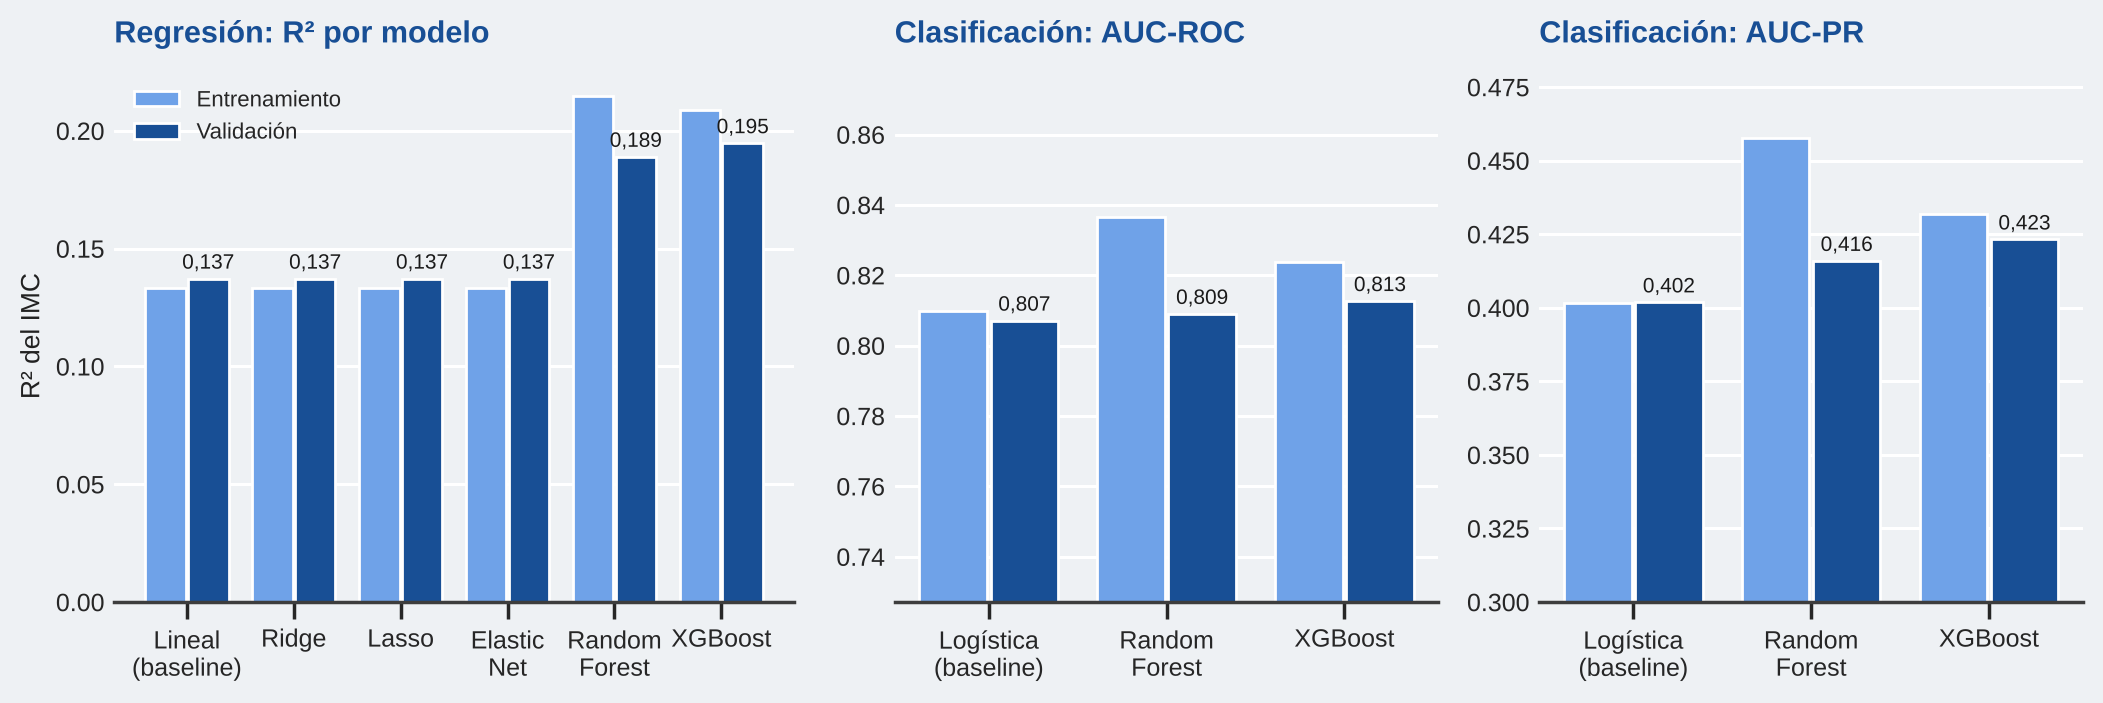

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(10.6, 3.6), gridspec_kw={"width_ratios": [1.25, 1, 1]})
r5 = reg5.drop(index="XGBoost (objetivo logarítmico)"); x = np.arange(len(r5))
axs[0].bar(x - .2, r5["R² (train)"], .38, color=CELESTE, label="Entrenamiento"); br = axs[0].bar(x + .2, r5["R² (val)"], .38, color=AZUL, label="Validación")
axs[0].bar_label(br, labels=[es(v, 3) for v in r5["R² (val)"]], fontsize=7.5, color=TINTA, padding=2)
axs[0].set_xticks(x, ["Lineal\n(baseline)", "Ridge", "Lasso", "Elastic\nNet", "Random\nForest", "XGBoost"]); axs[0].set(ylabel="R² del IMC", title="Regresión: R² por modelo"); axs[0].legend(loc="upper left", fontsize=8)
cv_ = clf5[clf5.Conjunto == "Validación"].set_index("Modelo"); ct_ = clf5[clf5.Conjunto == "Entrenamiento"].set_index("Modelo"); x = np.arange(len(cv_)); et = ["Logística\n(baseline)", "Random\nForest", "XGBoost"]
for ax, m, tit in [(axs[1], "AUC-ROC", "Clasificación: AUC-ROC"), (axs[2], "AUC-PR", "Clasificación: AUC-PR")]:
    ax.bar(x - .2, ct_[m], .38, color=CELESTE, label="Entrenamiento"); br = ax.bar(x + .2, cv_[m], .38, color=AZUL, label="Validación")
    ax.bar_label(br, labels=[es(v, 3) for v in cv_[m]], fontsize=7.5, color=TINTA, padding=2); ax.set_xticks(x, et); ax.set(title=tit, ylim=(min(.75, cv_[m].min() - .08) if m == "AUC-ROC" else .3, None))
fig.tight_layout(); fig.savefig(FIG / "fig1_modelos_act5.png"); plt.show()

**Lectura.** Con hiperparámetros iniciales, los dos ensambles superan a la regresión logística por un margen pequeño: el AUC-PR en validación pasa de 0,402 a 0,416 (Random Forest) y 0,423 (XGBoost). Random Forest presenta sobreajuste moderado (AUC-PR de 0,458 en entrenamiento); XGBoost, leve. El F1 con umbral de 0,5 es casi idéntico en los tres (≈ 0,44) porque todos operan en un punto de alto recall y baja precisión.

## 4. Aprendizaje no supervisado: segmentación de perfiles de riesgo
Se segmenta a la población con ocho variables cuantitativas y ordinales estandarizadas: IMC, grupo de edad, salud general, días de mala salud mental y física, nivel educativo, ingreso y número de condiciones cardiometabólicas (`CardioRisk`). **`Diabetes_binary` no se usa para agrupar**; se reserva para validar externamente los grupos. El escalador y los modelos se ajustan solo con entrenamiento.

### 4.1 K-Means: número óptimo de clústeres por el método del codo y el coeficiente de silueta

In [6]:
CL_VARS = ["BMI", "Age", "GenHlth", "MentHlth", "PhysHlth", "Education", "Income", "CardioRisk"]
ET_CL = {"BMI": "IMC", "Age": "Grupo de edad", "GenHlth": "Salud general (1–5)", "MentHlth": "Días mala salud mental", "PhysHlth": "Días mala salud física",
         "Education": "Nivel educativo", "Income": "Ingreso", "CardioRisk": "Condiciones cardiometabólicas"}
def vars_cluster(X):
    X = X.copy().astype(float); X["BMI"] = X["BMI"].clip(lo, hi); X["CardioRisk"] = X["HighBP"] + X["HighChol"] + X["HeartDiseaseorAttack"] + X["Stroke"]
    return X[CL_VARS]
Ctr = vars_cluster(X_train); esc_cl = StandardScaler().fit(Ctr); Ztr = esc_cl.transform(Ctr)
rng = np.random.default_rng(RANDOM_STATE); im = rng.choice(len(Ztr), 15000, replace=False); Zm = Ztr[im]     # muestra fija para la silueta (costo cuadrático)
ks = list(range(2, 9)); inercia, silueta, modelos_k = [], [], {}
for k in ks:
    km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Ztr); modelos_k[k] = km
    inercia.append(float(km.inertia_)); silueta.append(float(silhouette_score(Zm, km.labels_[im])))
caida = [None] + [100 * (inercia[i - 1] - inercia[i]) / inercia[i - 1] for i in range(1, len(ks))]
tk = pd.DataFrame({"k": ks, "Inercia": inercia, "Reducción de inercia (%)": caida, "Silueta": silueta}).set_index("k")
RES["kmeans_k"] = tk.reset_index().to_dict("records")
tk.round(3)

,Inercia,Reducción de inercia (%),Silueta
k,,,
2,1233457.507,NaN,0.248
3,1073722.625,12.950,0.170
4,977485.013,8.963,0.152
5,898576.585,8.073,0.161
6,837909.108,6.752,0.161
7,791992.333,5.480,0.141
8,751206.840,5.150,0.149


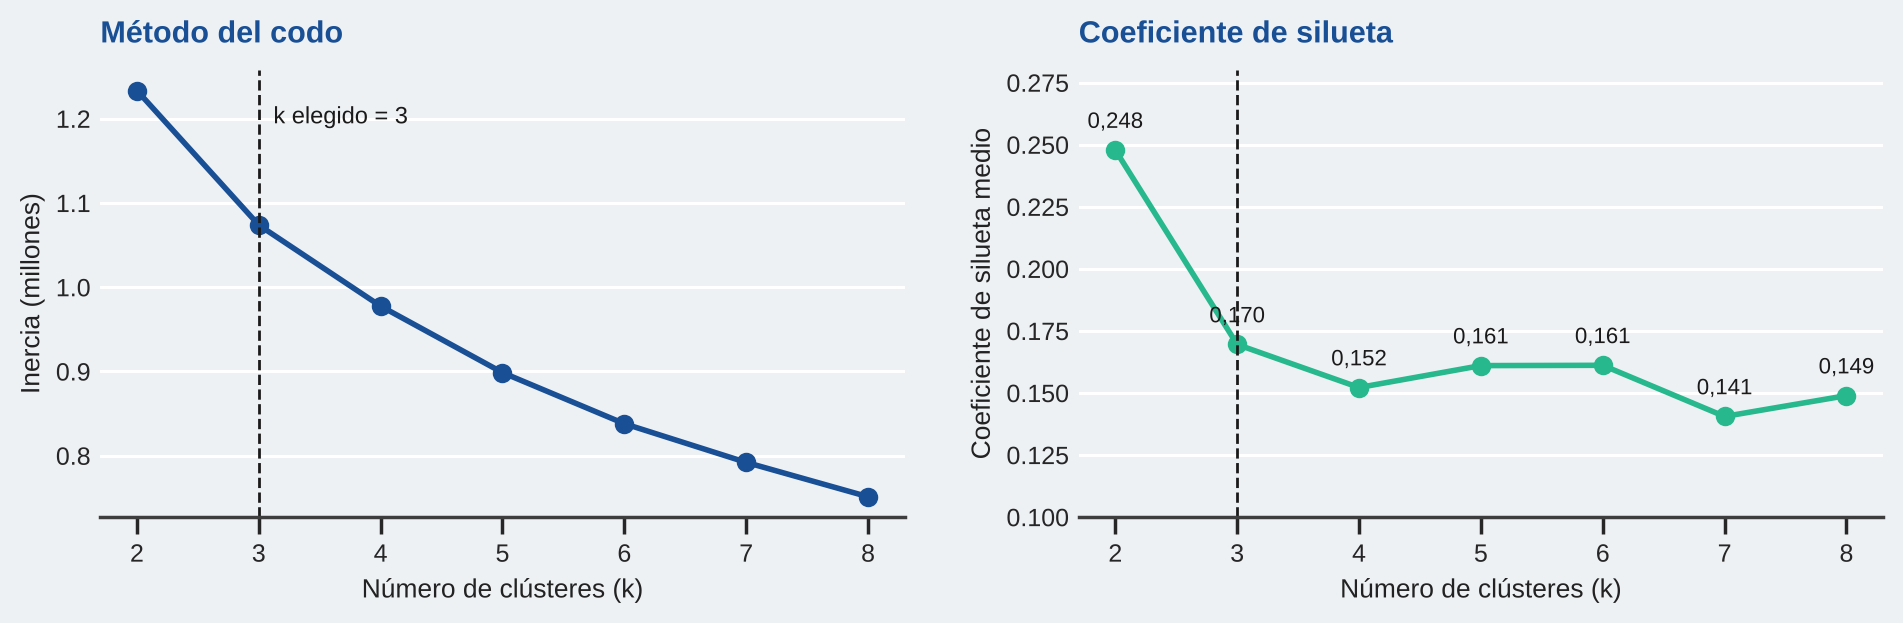

In [7]:
K = 3                                              # decisión justificada en el texto siguiente
km = modelos_k[K]; orden = np.argsort([-(km.labels_ == c).sum() for c in range(K)])   # numerar de mayor a menor tamaño
mapa = {int(o): i + 1 for i, o in enumerate(orden)}; lab_tr = pd.Series(km.labels_).map(mapa).values
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.2))
a1.plot(ks, np.array(inercia) / 1e6, color=AZUL, lw=2, marker="o", ms=6); a1.set(xlabel="Número de clústeres (k)", ylabel="Inercia (millones)", title="Método del codo")
a2.plot(ks, silueta, color=MENTA, lw=2, marker="o", ms=6); a2.set(xlabel="Número de clústeres (k)", ylabel="Coeficiente de silueta medio", title="Coeficiente de silueta", ylim=(.1, .28))
for k_, s_ in zip(ks, silueta): a2.annotate(es(s_, 3), (k_, s_), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8, color=TINTA)
for a_ in (a1, a2): a_.axvline(K, color=TINTA, lw=1, ls="--"); a_.set_xticks(ks)
a1.text(K + .12, max(inercia) / 1e6 * .985, f"k elegido = {K}", fontsize=8.5, color=TINTA, va="top")
fig.tight_layout(w_pad=2.5); fig.savefig(FIG / "fig2_codo_silueta.png"); plt.show()

**Determinación de K.** El coeficiente de silueta es máximo en k = 2 (0,25) y desciende a 0,17 en k = 3; el codo no es nítido, pero la reducción de inercia cae de 13 % (de 2 a 3 clústeres) a 9 % o menos en adelante. Los valores bajos de silueta indican que la población no forma grupos naturalmente separados, sino un continuo. Se adopta **k = 3**: es el segundo mejor valor de silueta, coincide con el último tramo de reducción apreciable de la inercia y, a diferencia de k = 2 (que solo separa «sanos» de «con riesgo»), distingue dos perfiles de riesgo de naturaleza distinta, lo que da valor práctico a la segmentación. Esta elección combina los criterios cuantitativos con la interpretabilidad y se declara como decisión del analista.

### 4.2 Perfil e interpretación de los clústeres

In [8]:
perf = Ctr.assign(cluster=lab_tr, Diabetes=y_train.values).groupby("cluster").agg(n=("BMI", "size"), **{v: (v, "mean") for v in CL_VARS}, diabetes=("Diabetes", "mean"))
perf["pct"] = 100 * perf.n / perf.n.sum()
extra = X_train.assign(cluster=lab_tr).groupby("cluster")[["HighBP", "HighChol", "PhysActivity", "DiffWalk", "Smoker", "Sex"]].mean()
zmed = pd.DataFrame(Ztr, columns=CL_VARS).groupby(lab_tr).mean()
chi = stats.chi2_contingency(pd.crosstab(lab_tr, y_train.values)); v_cramer = float(np.sqrt(chi[0] / (len(lab_tr) * 1)))
NOM = {1: "C1", 2: "C2", 3: "C3"}
RES["kmeans"] = {"k": K, "silueta": float(silueta[ks.index(K)]), "perfil": perf.reset_index().to_dict("records"), "extra": extra.reset_index().to_dict("records"),
                 "chi2": float(chi[0]), "p": float(chi[1]), "v_cramer": v_cramer, "z": zmed.reset_index(names="cluster").to_dict("records")}
print(f"Asociación clúster–diabetes: chi² = {chi[0]:,.0f}; V de Cramér = {v_cramer:.3f}")
perf.round(2)

Asociación clúster–diabetes: chi² = 15,600; V de Cramér = 0.286


,n,BMI,Age,GenHlth,MentHlth,PhysHlth,Education,Income,CardioRisk,diabetes,pct
cluster,,,,,,,,,,,
1,86762,27.37,5.92,2.04,3.37,1.34,5.46,5.36,0.36,0.04,45.44
2,75293,29.43,10.22,2.70,1.29,1.60,4.91,4.24,1.53,0.22,39.43
3,28883,31.16,8.32,3.89,14.31,21.09,4.67,3.49,1.43,0.28,15.13


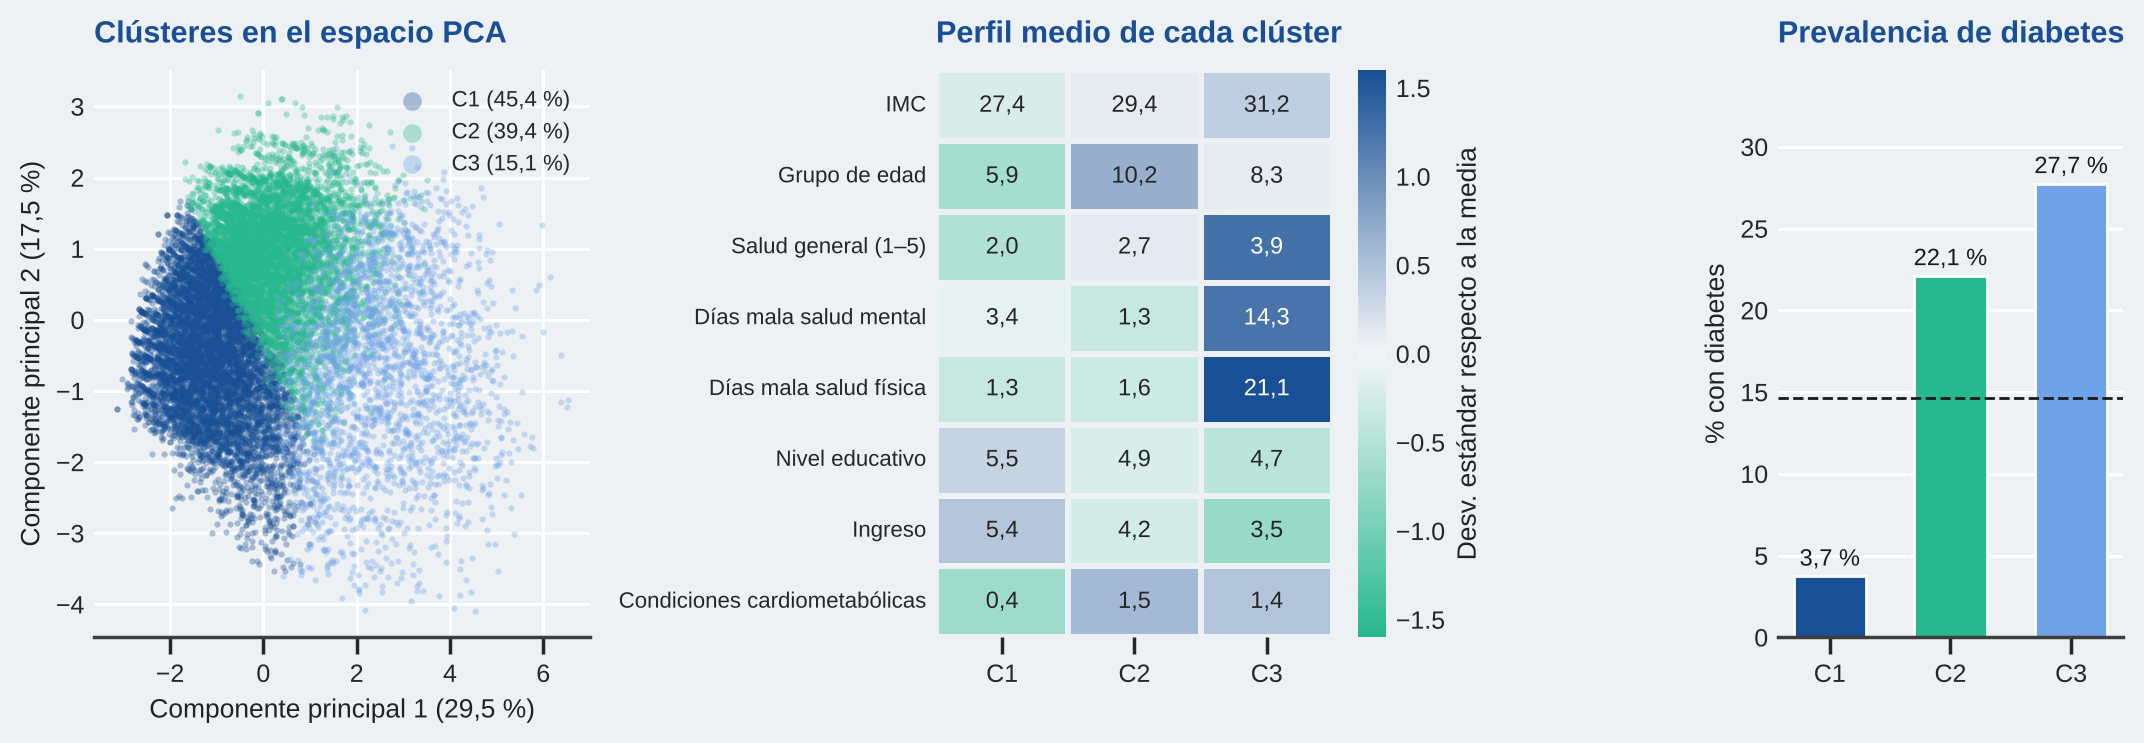

In [9]:
pca = PCA(2, random_state=RANDOM_STATE).fit(Ztr); Pm = pca.transform(Zm); lm = lab_tr[im]
RES["pca_var"] = [float(v) for v in pca.explained_variance_ratio_]
fig, axs = plt.subplots(1, 3, figsize=(10.8, 3.8), gridspec_kw={"width_ratios": [1.15, 1.15, .8]})
for c in range(1, K + 1): axs[0].scatter(Pm[lm == c, 0], Pm[lm == c, 1], s=5, alpha=.35, color=PALETA[c - 1], label=f"C{c} ({es(perf.loc[c, 'pct'], 1)} %)", linewidths=0)
axs[0].set(xlabel=f"Componente principal 1 ({es(100*pca.explained_variance_ratio_[0], 1)} %)", ylabel=f"Componente principal 2 ({es(100*pca.explained_variance_ratio_[1], 1)} %)", title="Clústeres en el espacio PCA")
axs[0].legend(loc="upper right", markerscale=3, fontsize=8); axs[0].grid(axis="x", color="white")
anot = perf[CL_VARS].T.copy(); anot.index = [ET_CL[v] for v in CL_VARS]
from matplotlib.colors import LinearSegmentedColormap
DIV = LinearSegmentedColormap.from_list("menta_azul", [MENTA, "#f4f6f8", AZUL])
zz = zmed.T.copy(); zz.index = anot.index; zz.columns = [f"C{c}" for c in zz.columns]
sns.heatmap(zz, annot=anot.round(1).astype(str).apply(lambda s: s.str.replace(".", ",")).values, fmt="", cmap=DIV, center=0, vmin=-1.6, vmax=1.6, linewidths=2, linecolor=FONDO,
            cbar_kws={"label": "Desv. estándar respecto a la media"}, annot_kws={"size": 8.5}, ax=axs[1])
axs[1].set(title="Perfil medio de cada clúster", xlabel=""); axs[1].tick_params(axis="y", labelsize=8, rotation=0)
br = axs[2].bar([f"C{c}" for c in perf.index], 100 * perf.diabetes, color=PALETA[:K], width=.6); axs[2].bar_label(br, labels=[es(v, 1) + " %" for v in 100 * perf.diabetes], fontsize=8.5, color=TINTA, padding=2)
axs[2].axhline(100 * y_train.mean(), color=TINTA, lw=1, ls="--"); axs[2].set(title="Prevalencia de diabetes", ylabel="% con diabetes", ylim=(0, 100 * perf.diabetes.max() * 1.25))
fig.tight_layout(); fig.savefig(FIG / "fig3_clusters.png"); plt.show()

**Interpretación de los clústeres** (medias en unidades originales; la prevalencia de diabetes no intervino en el agrupamiento):
- **C1 · Adultos jóvenes sanos y de mayor nivel socioeconómico (45 %).** Menor edad (grupo medio 5,9; alrededor de 45 años), IMC más bajo, mejor salud percibida, mayor educación e ingreso y casi sin condiciones cardiometabólicas. Prevalencia de diabetes: 3,7 %.
- **C2 · Adultos mayores con riesgo cardiometabólico (39 %).** Mayor edad (grupo 10,2; 65 a 69 años), hipertensión en el 69 % y colesterol alto en el 63 %, pero pocos días de mala salud. Prevalencia: 22,1 %.
- **C3 · Salud deteriorada y vulnerabilidad socioeconómica (15 %).** Peor salud percibida, 21 días de mala salud física y 14 de mala salud mental al mes, dificultad para caminar en el 51 %, el IMC más alto y el menor ingreso. Prevalencia: 27,7 %.

La asociación entre clúster y diabetes es sustancial (V de Cramér = 0,29). Los dos grupos de riesgo requieren intervenciones distintas: control clínico de factores cardiometabólicos en C2 y atención integral con enfoque social y de salud mental en C3.

### 4.3 Segundo algoritmo: DBSCAN, y clustering jerárquico aglomerativo como contraste
El objetivo específico 3 de la Fase 1 comprometió DBSCAN. Su parámetro `eps` se elige con el gráfico de distancias al k-ésimo vecino (k = `min_samples` = 16, el doble del número de variables). Dado su costo, DBSCAN y el método jerárquico se ajustan sobre muestras aleatorias del conjunto de entrenamiento.

In [10]:
MIN_S = 2 * len(CL_VARS)
kd = np.sort(NearestNeighbors(n_neighbors=MIN_S).fit(Zm).kneighbors(Zm)[0][:, -1])
filas = []
for eps in (0.8, 1.0, 1.2, 1.5, 2.0):
    l = DBSCAN(eps=eps, min_samples=MIN_S).fit(Zm).labels_; n_c = len(set(l)) - (1 if -1 in l else 0); tam = np.sort(np.bincount(l[l >= 0]))[::-1] if n_c else np.array([0])
    filas.append({"eps": eps, "Clústeres": n_c, "Ruido (%)": 100 * (l == -1).mean(), "Mayor clúster (%)": 100 * tam[0] / len(l),
                  "Silueta (sin ruido)": float(silhouette_score(Zm[l >= 0], l[l >= 0])) if n_c > 1 else np.nan})
db = pd.DataFrame(filas).set_index("eps"); EPS = 1.5
ldb = DBSCAN(eps=EPS, min_samples=MIN_S).fit(Zm).labels_
prev_db = {"ruido": float(y_train.values[im][ldb == -1].mean()), "principal": float(y_train.values[im][ldb == np.bincount(ldb[ldb >= 0]).argmax()].mean())}
# Jerárquico aglomerativo (Ward) sobre 8.000 registros y comparación con K-Means
i8 = im[:8000]; ag = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Ztr[i8])
sil_ag = float(silhouette_score(Ztr[i8], ag.labels_)); sil_km8 = float(silhouette_score(Ztr[i8], lab_tr[i8])); ari = float(adjusted_rand_score(lab_tr[i8], ag.labels_))
prev_ag = sorted([float(y_train.values[i8][ag.labels_ == c].mean()) for c in range(K)]); tam_ag = sorted([float(100 * (ag.labels_ == c).mean()) for c in range(K)], reverse=True)
RES["dbscan"] = {"tabla": db.reset_index().to_dict("records"), "eps": EPS, "min_samples": MIN_S, "kdist": {str(p): float(np.percentile(kd, p)) for p in (50, 75, 90, 95, 99)}, "prev": prev_db,
                 "ruido_pct": float(100 * (ldb == -1).mean())}
RES["jerarquico"] = {"silueta": sil_ag, "silueta_kmeans_misma_muestra": sil_km8, "ari": ari, "prev": prev_ag, "tam": tam_ag}
print(f"Jerárquico (Ward, k = {K}): silueta = {sil_ag:.3f} | K-Means en la misma muestra: {sil_km8:.3f} | ARI entre ambos = {ari:.3f}")
print("Prevalencia de diabetes por clúster jerárquico:", [f"{100*v:.1f} %" for v in prev_ag])
db.round(3)

Jerárquico (Ward, k = 3): silueta = 0.133 | K-Means en la misma muestra: 0.171 | ARI entre ambos = 0.474
Prevalencia de diabetes por clúster jerárquico: ['6.1 %', '20.1 %', '22.7 %']


,Clústeres,Ruido (%),Mayor clúster (%),Silueta (sin ruido)
eps,,,,
0.8,27,46.113,7.340,0.092
1.0,5,34.567,29.093,0.070
1.2,5,21.787,76.027,0.205
1.5,4,7.947,88.367,0.253
2.0,1,0.640,99.360,NaN


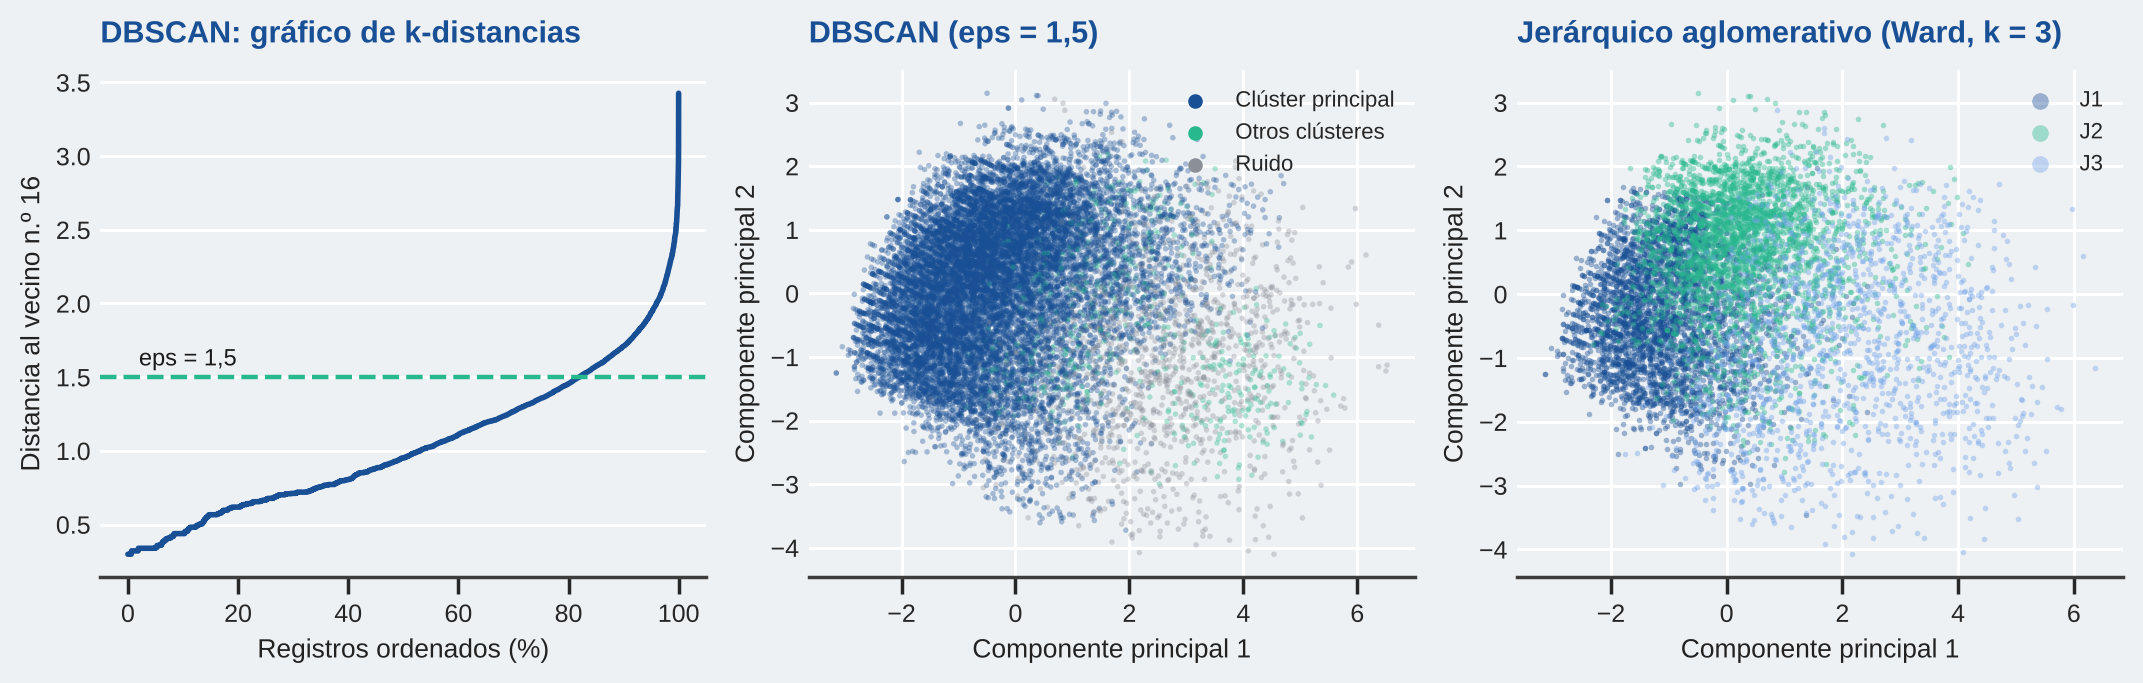

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(10.8, 3.5))
axs[0].plot(np.arange(len(kd)) / len(kd) * 100, kd, color=AZUL, lw=2); axs[0].axhline(EPS, color=MENTA, lw=1.6, ls="--"); axs[0].text(2, EPS + .08, f"eps = {es(EPS, 1)}", fontsize=8.5, color=TINTA)
axs[0].set(xlabel="Registros ordenados (%)", ylabel=f"Distancia al vecino n.º {MIN_S}", title="DBSCAN: gráfico de k-distancias")
col_db = np.where(ldb == -1, "#8a8f98", np.where(ldb == np.bincount(ldb[ldb >= 0]).argmax(), AZUL, MENTA))
axs[1].scatter(Pm[:, 0], Pm[:, 1], s=4, alpha=.35, c=col_db, linewidths=0); axs[1].set(xlabel="Componente principal 1", ylabel="Componente principal 2", title=f"DBSCAN (eps = {es(EPS, 1)})"); axs[1].grid(axis="x", color="white")
for lab_, col_ in [("Clúster principal", AZUL), ("Otros clústeres", MENTA), ("Ruido", "#8a8f98")]: axs[1].scatter([], [], s=18, color=col_, label=lab_)
axs[1].legend(loc="upper right", fontsize=8)
P8 = pca.transform(Ztr[i8]); og = np.argsort([-(ag.labels_ == c).sum() for c in range(K)])
for j, c in enumerate(og): axs[2].scatter(P8[ag.labels_ == c, 0], P8[ag.labels_ == c, 1], s=4, alpha=.4, color=PALETA[j], linewidths=0, label=f"J{j + 1}")
axs[2].set(xlabel="Componente principal 1", ylabel="Componente principal 2", title=f"Jerárquico aglomerativo (Ward, k = {K})"); axs[2].legend(loc="upper right", markerscale=3, fontsize=8); axs[2].grid(axis="x", color="white")
fig.tight_layout(); fig.savefig(FIG / "fig4_dbscan_jerarquico.png"); plt.show()

**Lectura.**
- **DBSCAN** no produce una segmentación útil: con `eps` = 1,5 agrupa al 88 % de la muestra en un solo clúster y deja un 8 % como ruido; con valores menores fragmenta los datos y multiplica el ruido. Al ser variables discretas de una encuesta, los registros forman una nube continua, sin regiones de baja densidad que separen grupos. Su aporte es identificar perfiles atípicos: la prevalencia de diabetes en el ruido (25 %) casi duplica la del clúster principal (13 %).
- El **clustering jerárquico** (Ward) recupera una estructura parecida a la de K-Means (índice de Rand ajustado de 0,47 y el mismo gradiente de prevalencia: 6 %, 20 % y 23 %), con una silueta menor (0,13 frente a 0,17). La coincidencia parcial respalda la existencia de los tres perfiles, aunque con fronteras difusas.
- Se adopta **K-Means con k = 3** para el tablero de la Fase 4, por su mejor silueta, su escalabilidad al conjunto completo y la posibilidad de asignar nuevos registros.

# ACTIVIDAD 6 · EVALUACIÓN COMPARATIVA, OPTIMIZACIÓN E INTERPRETABILIDAD
## 5. Búsqueda de hiperparámetros con validación cruzada
Se optimizan los tres ensambles con `RandomizedSearchCV` y validación cruzada de 3 pliegues sobre entrenamiento (estratificada en clasificación). El preprocesamiento va dentro del `Pipeline`, de modo que se reajusta en cada pliegue. La métrica de selección es el **AUC-PR** en clasificación (adecuada al desbalance) y el **RMSE** en regresión. Los modelos lineales regularizados ya eligieron su penalización por validación cruzada en la sección 2.

In [12]:
skf = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE); kf3 = KFold(3, shuffle=True, random_state=RANDOM_STATE)
esp_xgb = {"modelo__n_estimators": [200, 400, 600, 800], "modelo__max_depth": [3, 4, 5, 6], "modelo__learning_rate": [0.02, 0.03, 0.05, 0.1],
           "modelo__subsample": [0.7, 0.85, 1.0], "modelo__colsample_bytree": [0.6, 0.8, 1.0], "modelo__min_child_weight": [1, 5, 10], "modelo__reg_lambda": [1, 5, 10]}
esp_rf = {"modelo__max_depth": [8, 12, 16, None], "modelo__min_samples_leaf": [10, 20, 50], "modelo__max_features": ["sqrt", 0.3, 0.5]}
busq = {}
t = time.time(); busq["XGBoost (clasificación)"] = RandomizedSearchCV(pipe_arbol_clf(XGBClassifier(**XGBC)), esp_xgb, n_iter=15, cv=skf, scoring="average_precision",
                                                                    random_state=RANDOM_STATE, n_jobs=1, refit=True).fit(X_train, y_train); t1 = time.time() - t
t = time.time(); busq["Random Forest (clasificación)"] = RandomizedSearchCV(pipe_arbol_clf(RandomForestClassifier(**{**RFC, "n_estimators": 100})), esp_rf, n_iter=6, cv=skf,
                                                                          scoring="average_precision", random_state=RANDOM_STATE, n_jobs=1, refit=False).fit(X_train, y_train); t2 = time.time() - t
t = time.time(); busq["XGBoost (regresión)"] = RandomizedSearchCV(pipe_reg_arbol(XGBRegressor(**XGBR)), esp_xgb, n_iter=12, cv=kf3, scoring="neg_root_mean_squared_error",
                                                                random_state=RANDOM_STATE, n_jobs=1, refit=True).fit(Rtr, ytr_w); t3 = time.time() - t
xgb_opt = busq["XGBoost (clasificación)"].best_estimator_
rf_opt = pipe_arbol_clf(RandomForestClassifier(**{**RFC, **{k.replace("modelo__", ""): v for k, v in busq["Random Forest (clasificación)"].best_params_.items()}})).fit(X_train, y_train)
xgbr_opt = busq["XGBoost (regresión)"].best_estimator_
def cv_inicial(pipe, X, y, cv, scoring):
    from sklearn.model_selection import cross_val_score
    return float(cross_val_score(pipe, X, y, cv=cv, scoring=scoring, n_jobs=1).mean())
ini = {"XGBoost (clasificación)": cv_inicial(pipe_arbol_clf(XGBClassifier(**XGBC)), X_train, y_train, skf, "average_precision"),
       "Random Forest (clasificación)": cv_inicial(pipe_arbol_clf(RandomForestClassifier(**{**RFC, "n_estimators": 100})), X_train, y_train, skf, "average_precision"),
       "XGBoost (regresión)": -cv_inicial(pipe_reg_arbol(XGBRegressor(**XGBR)), Rtr, ytr_w, kf3, "neg_root_mean_squared_error")}
hp = pd.DataFrame([{"Modelo": n, "Métrica (CV)": "AUC-PR" if "clasif" in n else "RMSE", "Configuraciones": len(b.cv_results_["params"]), "Ajustes": len(b.cv_results_["params"]) * 3,
    "Inicial": ini[n], "Optimizado": abs(b.best_score_), "Desv. entre pliegues": float(b.cv_results_["std_test_score"][b.best_index_]),
    "Mejores hiperparámetros": ", ".join(f"{k.replace('modelo__', '')} = {v}" for k, v in sorted(b.best_params_.items())), "Tiempo (s)": tt} for (n, b), tt in zip(busq.items(), (t1, t2, t3))]).set_index("Modelo")
RES["hiperparametros"] = hp.reset_index().to_dict("records")
pd.set_option("display.max_colwidth", 200); hp.round(4)

,Métrica (CV),Configuraciones,Ajustes,Inicial,Optimizado,Desv. entre pliegues,Mejores hiperparámetros,Tiempo (s)
Modelo,,,,,,,,
XGBoost (clasificación),AUC-PR,15,45,0.4153,0.4164,0.0026,"colsample_bytree = 0.8, learning_rate = 0.03, max_depth = 5, min_child_weight = 1, n_estimators = 400, reg_lambda = 10, subsample = 0.7",114.6068
Random Forest (clasificación),AUC-PR,6,18,0.4100,0.4108,0.0037,"max_depth = None, max_features = 0.3, min_samples_leaf = 20",46.2591
XGBoost (regresión),RMSE,12,36,5.5924,5.5901,0.0107,"colsample_bytree = 0.6, learning_rate = 0.03, max_depth = 6, min_child_weight = 1, n_estimators = 400, reg_lambda = 5, subsample = 0.85",88.0822


**Lectura.** La búsqueda apenas mejora los valores iniciales: el AUC-PR en validación cruzada pasa de 0,415 a 0,416 en XGBoost y de 0,410 a 0,411 en Random Forest, y el RMSE de 5,592 a 5,590. Las diferencias son menores que la desviación entre pliegues. Es un resultado informativo: el desempeño no está limitado por la configuración de los algoritmos sino por la información que contienen las variables. La búsqueda favorece modelos más regularizados (tasa de aprendizaje baja, submuestreo y mayor penalización L2).

## 6. Perceptrón multicapa (MLP) en PyTorch
Red densa para clasificación binaria con dos capas ocultas (64 y 32 neuronas, activación ReLU y *dropout* de 0,2). Entrada: las 24 variables del preprocesador lineal de la Fase 2 (estandarizadas, ajustado solo con entrenamiento). Función de pérdida: entropía cruzada binaria con `pos_weight` igual a la razón de desbalance. Optimizador Adam con decaimiento de pesos (regularización L2) y **parada temprana** según la pérdida de validación, para prevenir el sobreajuste.

Parámetros: 3,713 | épocas ejecutadas: 25 | mejor época: 19 | pérdida train 0.8825 / validación 0.8958


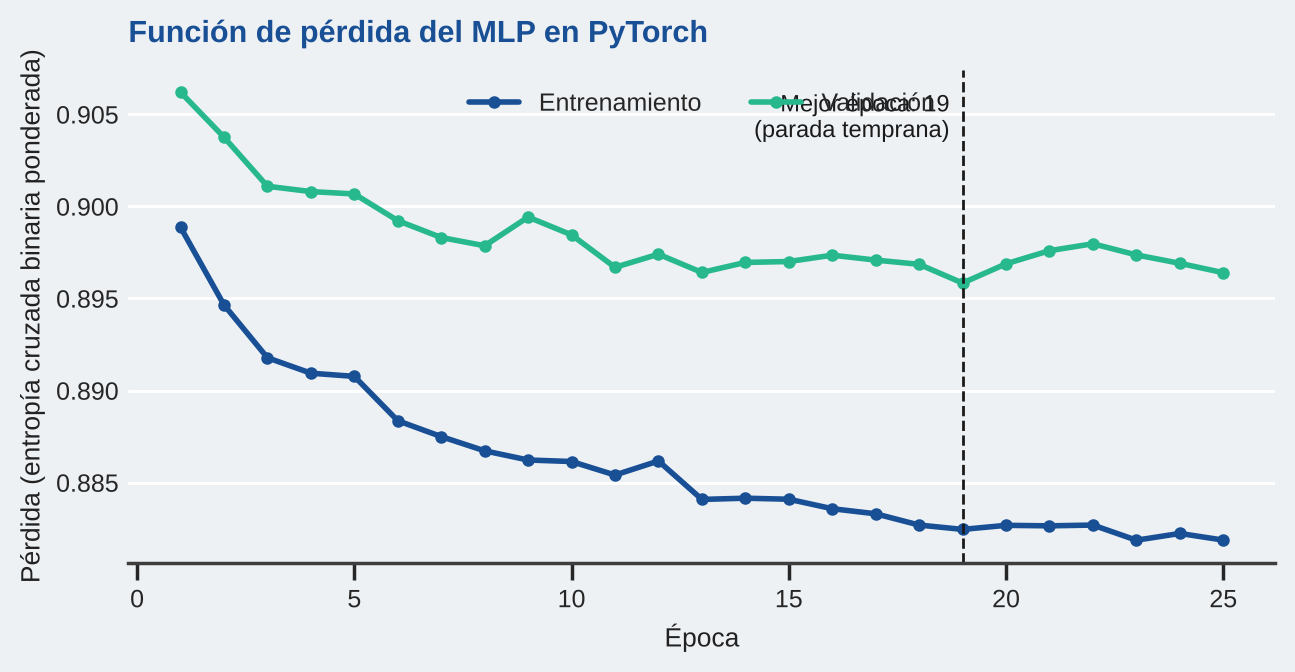

In [13]:
prep_mlp = Pipeline([("recorte", Winsorizer()), ("derivadas", FunctionTransformer(crear_variables)),
                     ("prep", preprocesador(["BMI", "MentHlth", "PhysHlth", "UnhealthyDays", "Age_BMI"], BIN))]).fit(X_train)
tens = lambda X: torch.tensor(prep_mlp.transform(X), dtype=torch.float32)
Ttr, Tva, Tte = tens(X_train), tens(X_val), tens(X_test)
ttr, tva = torch.tensor(y_train.values, dtype=torch.float32), torch.tensor(y_val.values, dtype=torch.float32)

class MLP(nn.Module):
    def __init__(self, n_entrada, ocultas=(64, 32), dropout=0.2):
        super().__init__(); capas, n = [], n_entrada
        for h in ocultas: capas += [nn.Linear(n, h), nn.ReLU(), nn.Dropout(dropout)]; n = h
        self.red = nn.Sequential(*capas, nn.Linear(n, 1))
    def forward(self, x): return self.red(x).squeeze(1)

torch.manual_seed(RANDOM_STATE); red = MLP(Ttr.shape[1])
perdida = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(RATIO)); opt = torch.optim.Adam(red.parameters(), lr=1e-3, weight_decay=1e-4)
LOTE, EPOCAS, PACIENCIA = 1024, 60, 6; hist = {"train": [], "val": []}; mejor, espera, mejor_estado = np.inf, 0, None
g = torch.Generator().manual_seed(RANDOM_STATE)
for ep in range(1, EPOCAS + 1):
    red.train(); perm = torch.randperm(len(Ttr), generator=g); acum = 0.0
    for i in range(0, len(Ttr), LOTE):
        idx = perm[i:i + LOTE]; opt.zero_grad(); l = perdida(red(Ttr[idx]), ttr[idx]); l.backward(); opt.step(); acum += l.item() * len(idx)
    red.eval()
    with torch.no_grad(): lv = perdida(red(Tva), tva).item(); lt = perdida(red(Ttr), ttr).item()      # pérdida de train medida sin dropout, comparable con validación
    hist["train"].append(lt); hist["val"].append(lv)
    if lv < mejor - 1e-4: mejor, espera, mejor_estado, mejor_ep = lv, 0, {k: v.clone() for k, v in red.state_dict().items()}, ep
    else:
        espera += 1
        if espera >= PACIENCIA: break
red.load_state_dict(mejor_estado); red.eval()
proba_mlp = lambda T: torch.sigmoid(red(T)).detach().numpy()
n_par = sum(p.numel() for p in red.parameters())
RES["mlp"] = {"arquitectura": f"{Ttr.shape[1]}–64–32–1", "parametros": int(n_par), "epocas": len(hist["train"]), "mejor_epoca": int(mejor_ep), "hist": hist,
              "loss_train": float(hist["train"][mejor_ep - 1]), "loss_val": float(mejor), "lote": LOTE, "paciencia": PACIENCIA}
print(f"Parámetros: {n_par:,} | épocas ejecutadas: {len(hist['train'])} | mejor época: {mejor_ep} | pérdida train {hist['train'][mejor_ep-1]:.4f} / validación {mejor:.4f}")
fig, ax = plt.subplots(figsize=(7.4, 3.2)); e_ = np.arange(1, len(hist["train"]) + 1)
ax.plot(e_, hist["train"], color=AZUL, lw=2, marker="o", ms=3.5, label="Entrenamiento"); ax.plot(e_, hist["val"], color=MENTA, lw=2, marker="o", ms=3.5, label="Validación")
ax.axvline(mejor_ep, color=TINTA, lw=1, ls="--"); ax.text(mejor_ep - .3, max(hist["train"][0], hist["val"][0]), f"Mejor época: {mejor_ep}\n(parada temprana)", fontsize=8.5, color=TINTA, va="top", ha="right")
ax.set(xlabel="Época", ylabel="Pérdida (entropía cruzada binaria ponderada)", title="Función de pérdida del MLP en PyTorch"); ax.legend(loc="upper center", ncol=2)
fig.savefig(FIG / "fig5_perdida_mlp.png"); plt.show()

**Lectura.** La pérdida de entrenamiento y la de validación descienden juntas y se estabilizan; la separación entre ambas es pequeña (0,882 frente a 0,896 en la mejor época) y la parada temprana detiene el entrenamiento cuando la validación deja de mejorar. No hay sobreajuste. La red tiene 3.713 parámetros, una capacidad acorde con 24 variables de entrada.

## 7. Punto de operación y evaluación final en el conjunto de prueba
Para cada clasificador se elige en **validación** el umbral que maximiza el F1 de la clase diabetes. Luego, por primera y única vez, se evalúan todos los modelos finales sobre el **conjunto de prueba**, que no intervino en ninguna decisión anterior.

In [14]:
finales = {"Regresión logística (baseline)": lambda X: clfs["Regresión logística (baseline Fase 2)"].predict_proba(X)[:, 1],
           "Random Forest (optimizado)": lambda X: rf_opt.predict_proba(X)[:, 1], "XGBoost (optimizado)": lambda X: xgb_opt.predict_proba(X)[:, 1],
           "MLP (PyTorch)": lambda X: proba_mlp(tens(X))}
P = {n: {"train": f(X_train), "val": f(X_val), "test": f(X_test)} for n, f in finales.items()}
def umbral_f1(y, p):
    pr, rc, th = precision_recall_curve(y, p); f1 = 2 * pr * rc / (pr + rc + 1e-12); return float(th[np.argmax(f1[:-1])])
UMB = {n: umbral_f1(y_val, P[n]["val"]) for n in finales}
filas, sobre = [], []
for n in finales:
    filas.append({"Modelo": n, "Umbral": 0.5, **metricas_clf(y_test, P[n]["test"], 0.5)})
    filas.append({"Modelo": n, "Umbral": UMB[n], **metricas_clf(y_test, P[n]["test"], UMB[n])})
    for conj, y_ in [("train", y_train), ("val", y_val), ("test", y_test)]:
        m = metricas_clf(y_, P[n][conj], 0.5); sobre.append({"Modelo": n, "Conjunto": conj, "F1": m["F1"], "AUC-ROC": m["AUC-ROC"], "AUC-PR": m["AUC-PR"]})
test_clf = pd.DataFrame(filas); RES["test_clf"] = filas; RES["umbrales"] = UMB; RES["sobreajuste_clf"] = sobre
MEJOR = max(finales, key=lambda n: average_precision_score(y_val, P[n]["val"])); RES["mejor_clf"] = MEJOR     # el mejor se elige en validación, no en prueba
print("Mejor clasificador según validación (AUC-PR):", MEJOR)
test_clf.set_index(["Modelo", "Umbral"]).round(3)

Mejor clasificador según validación (AUC-PR): XGBoost (optimizado)


Accuracy  Precision  Recall     F1  \
Modelo                         Umbral                                         
Regresión logística (baseline) 0.500000     0.723      0.313   0.749  0.441   
                               0.573373     0.766      0.344   0.664  0.453   
Random Forest (optimizado)     0.500000     0.741      0.326   0.727  0.451   
                               0.581653     0.791      0.369   0.607  0.459   
XGBoost (optimizado)           0.500000     0.708      0.306   0.787  0.441   
                               0.619237     0.782      0.362   0.640  0.462   
MLP (PyTorch)                  0.500000     0.713      0.309   0.781  0.443   
                               0.629635     0.788      0.367   0.624  0.462   

                                         F1 ponderado  AUC-ROC  AUC-PR  
Modelo                         Umbral                                   
Regresión logística (baseline) 0.500000         0.761    0.810   0.399  
                               0.573373         0.793    0.810   0.399  
Random Forest (optimizado)     0.500000         0.775    0.813   0.409  
                               0.581653         0.810    0.813   0.409  
XGBoost (optimizado)           0.500000         0.750    0.816   0.413  
                               0.619237         0.805    0.816   0.413  
MLP (PyTorch)                  0.500000         0.753    0.816   0.413  
                               0.629635         0.809    0.816   0.413

In [15]:
# Intervalos de confianza por bootstrap (400 remuestreos del conjunto de prueba) y diferencia frente al baseline
rb = np.random.default_rng(RANDOM_STATE); nt = len(y_test); yt = y_test.values; B_ = 400; base_n = "Regresión logística (baseline)"
bs = {n: {"AUC-ROC": [], "AUC-PR": [], "F1": []} for n in finales}
for _ in range(B_):
    ix = rb.integers(0, nt, nt); yy = yt[ix]
    for n in finales:
        pp = P[n]["test"][ix]; bs[n]["AUC-ROC"].append(roc_auc_score(yy, pp)); bs[n]["AUC-PR"].append(average_precision_score(yy, pp)); bs[n]["F1"].append(f1_score(yy, pp >= UMB[n]))
ic = lambda a: [float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))]
RES["bootstrap"] = {n: {m: ic(v) for m, v in d.items()} for n, d in bs.items()}
RES["bootstrap_dif"] = {n: {m: {"dif": float(np.mean(np.array(bs[n][m]) - np.array(bs[base_n][m]))), "ic": ic(np.array(bs[n][m]) - np.array(bs[base_n][m]))} for m in ("AUC-ROC", "AUC-PR", "F1")} for n in finales if n != base_n}
pd.DataFrame({n: {m: f"{d['dif']:+.4f}  [{d['ic'][0]:+.4f}, {d['ic'][1]:+.4f}]" for m, d in v.items()} for n, v in RES["bootstrap_dif"].items()}).T

,AUC-ROC,AUC-PR,F1
Random Forest (optimizado),"+0.0025 [+0.0007, +0.0041]","+0.0100 [+0.0053, +0.0153]","+0.0061 [+0.0016, +0.0110]"
XGBoost (optimizado),"+0.0056 [+0.0041, +0.0071]","+0.0142 [+0.0089, +0.0192]","+0.0092 [+0.0050, +0.0135]"
MLP (PyTorch),"+0.0056 [+0.0041, +0.0070]","+0.0137 [+0.0097, +0.0173]","+0.0094 [+0.0048, +0.0139]"


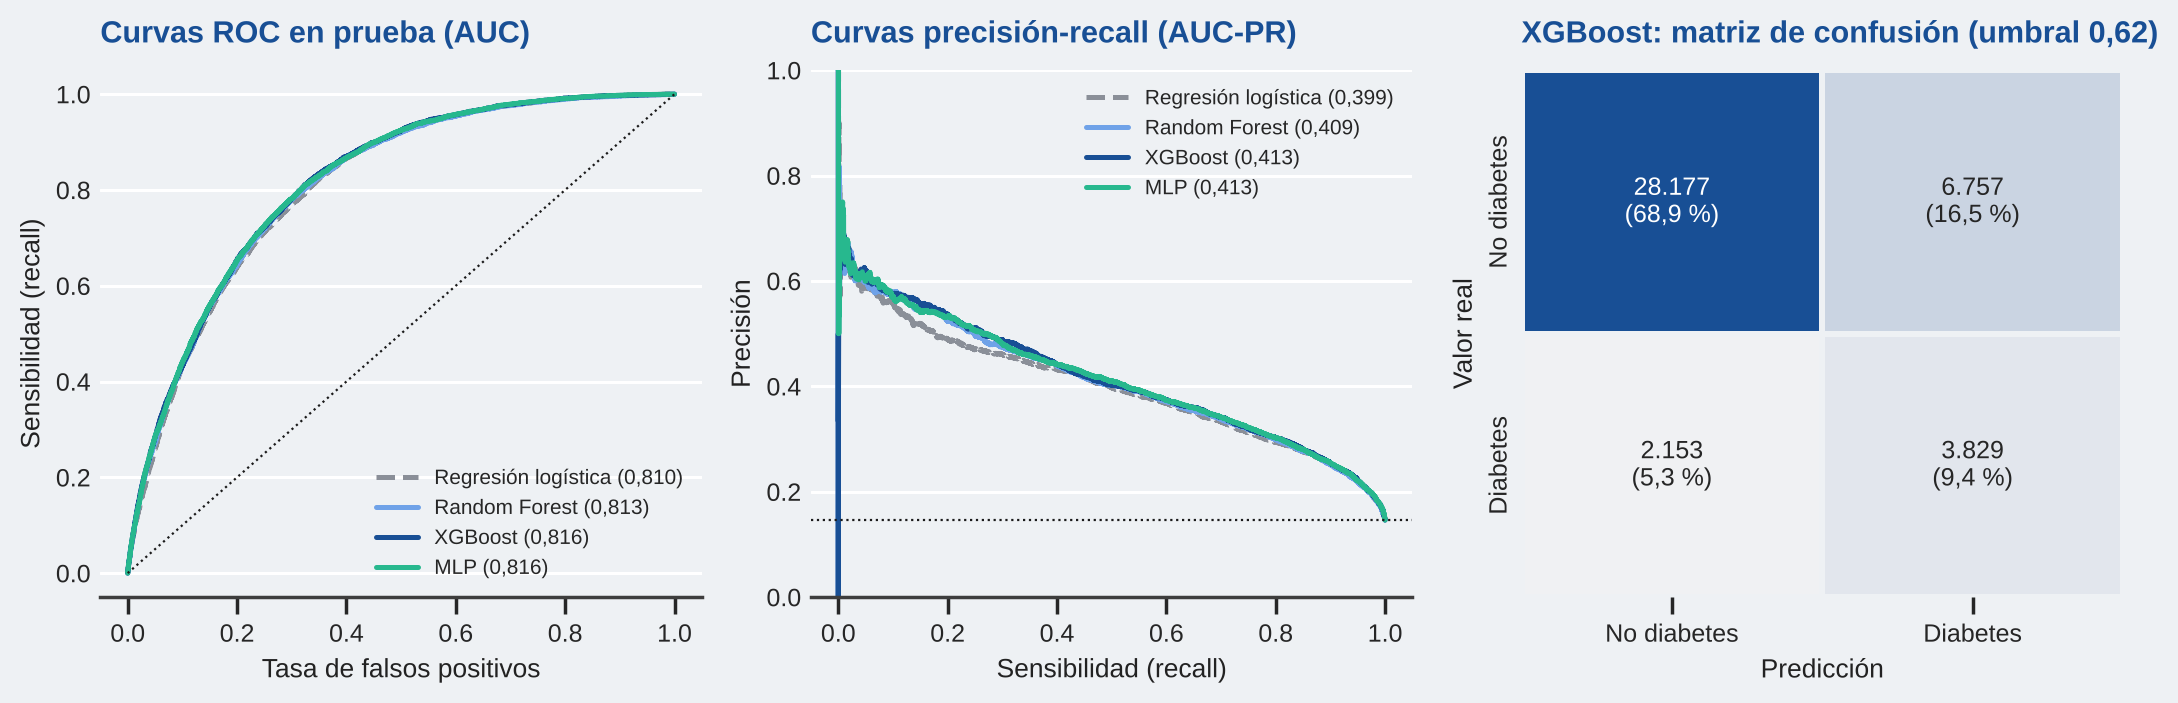

In [16]:
pm = P[MEJOR]["test"]; um = UMB[MEJOR]; cm5 = confusion_matrix(y_test, (pm >= .5).astype(int)); cmu = confusion_matrix(y_test, (pm >= um).astype(int))
RES["cm_mejor"] = {"0.5": cm5.tolist(), "umbral": cmu.tolist()}
fig, axs = plt.subplots(1, 3, figsize=(10.8, 3.6))
for (n, f), col, ls in zip(finales.items(), ["#8a8f98", CELESTE, AZUL, MENTA], ["--", "-", "-", "-"]):
    fpr, tpr, _ = roc_curve(y_test, P[n]["test"]); axs[0].plot(fpr, tpr, color=col, lw=1.8, ls=ls, label=f"{n.split(' (')[0]} ({es(roc_auc_score(y_test, P[n]['test']), 3)})")
    pr_, rc_, _ = precision_recall_curve(y_test, P[n]["test"]); axs[1].plot(rc_, pr_, color=col, lw=1.8, ls=ls, label=f"{n.split(' (')[0]} ({es(average_precision_score(y_test, P[n]['test']), 3)})")
axs[0].plot([0, 1], [0, 1], color=TINTA, lw=.8, ls=":"); axs[0].set(xlabel="Tasa de falsos positivos", ylabel="Sensibilidad (recall)", title="Curvas ROC en prueba (AUC)"); axs[0].legend(loc="lower right", fontsize=7.5)
axs[1].axhline(y_test.mean(), color=TINTA, lw=.8, ls=":"); axs[1].set(xlabel="Sensibilidad (recall)", ylabel="Precisión", title="Curvas precisión-recall (AUC-PR)", ylim=(0, 1)); axs[1].legend(loc="upper right", fontsize=7.5)
sns.heatmap(cmu, annot=np.array([[f"{es(v)}\n({es(100*v/cmu.sum(), 1)} %)" for v in r] for r in cmu]), fmt="", cmap=sns.light_palette(AZUL, as_cmap=True), cbar=False, linewidths=2, linecolor=FONDO,
            xticklabels=["No diabetes", "Diabetes"], yticklabels=["No diabetes", "Diabetes"], annot_kws={"size": 9}, ax=axs[2])
axs[2].set(xlabel="Predicción", ylabel="Valor real", title=f"{MEJOR.split(' (')[0]}: matriz de confusión (umbral {es(um, 2)})")
fig.tight_layout(); fig.savefig(FIG / "fig6_test_clasificacion.png"); plt.show()

In [17]:
# Regresión: evaluación final en prueba
reg_fin = {"Regresión lineal (baseline)": regs["Regresión lineal (baseline Fase 2)"], "ElasticNet": regs["ElasticNet"], "Random Forest": regs["Random Forest"], "XGBoost (optimizado)": xgbr_opt}
filas = []
for n, p in reg_fin.items():
    for conj, R_, y_ in [("train", Rtr, ytr_raw), ("val", Rva, yva_raw), ("test", Rte, yte_raw)]: filas.append({"Modelo": n, "Conjunto": conj, **mreg(y_, p.predict(R_))})
test_reg = pd.DataFrame(filas); RES["test_reg"] = filas
pr_x = xgbr_opt.predict(Rte); br2 = [r2_score(yte_raw.values[ix], pr_x[ix]) for ix in (rb.integers(0, nt, nt) for _ in range(400))]; RES["r2_ic"] = ic(br2)
print(f"R² en prueba de XGBoost optimizado: {r2_score(yte_raw, pr_x):.4f}  IC 95 % [{RES['r2_ic'][0]:.4f}, {RES['r2_ic'][1]:.4f}]")
test_reg.pivot(index="Modelo", columns="Conjunto", values=["R²", "RMSE", "MAE"]).loc[list(reg_fin)].round(3)

R² en prueba de XGBoost optimizado: 0.1856  IC 95 % [0.1780, 0.1932]


R²                 RMSE                  MAE  \
Conjunto                      test  train    val   test  train    val   test   
Modelo                                                                         
Regresión lineal (baseline)  0.130  0.133  0.137  6.068  6.070  6.102  4.511   
ElasticNet                   0.130  0.133  0.137  6.068  6.070  6.102  4.510   
Random Forest                0.180  0.215  0.189  5.894  5.777  5.917  4.364   
XGBoost (optimizado)         0.186  0.210  0.195  5.872  5.796  5.894  4.347   

                                           
Conjunto                     train    val  
Modelo                                     
Regresión lineal (baseline)  4.512  4.512  
ElasticNet                   4.512  4.512  
Random Forest                4.271  4.354  
XGBoost (optimizado)         4.289  4.334

**Lectura de la evaluación final.**
- **Clasificación.** XGBoost y el MLP empatan como mejores modelos en prueba (AUC-ROC = 0,816; AUC-PR = 0,413), seguidos de Random Forest (0,813; 0,409) y de la regresión logística (0,810; 0,399). La mejora frente al baseline es pequeña pero estadísticamente distinguible: el intervalo de confianza por bootstrap de la diferencia no incluye el cero.
- **Punto de operación.** Con umbral de 0,5, XGBoost detecta el 79 % de los diabéticos con una precisión de 0,31. Con el umbral que maximiza el F1 (0,62) el recall baja a 0,64 y la precisión sube a 0,36 (F1 = 0,46).
- **Sobreajuste.** XGBoost, el MLP y la regresión logística tienen métricas casi iguales en entrenamiento, validación y prueba. Random Forest es el único con una brecha apreciable (AUC-PR de 0,465 en entrenamiento y 0,409 en prueba).
- **Regresión.** XGBoost optimizado alcanza un R² de 0,186 en prueba (IC 95 %: 0,178 a 0,193), frente a 0,130 del modelo lineal.

## 8. Interpretabilidad
Se calculan valores **SHAP** (TreeSHAP) para el XGBoost optimizado de clasificación sobre una muestra de 5.000 registros de validación. Cada valor SHAP indica cuánto desplaza una variable la predicción de un individuo respecto al promedio, en escala logarítmica de odds. Se contrasta con la **importancia por permutación** (caída del AUC-PR al desordenar cada variable) y con la importancia del Random Forest. Para la regresión se reportan los valores SHAP del XGBoost del IMC.

In [18]:
mu = X_val.sample(5000, random_state=RANDOM_STATE); Xs = vars_arbol(xgb_opt.named_steps["recorte"].transform(mu)); FEAT = list(Xs.columns)
try:
    sv = shap.TreeExplainer(xgb_opt.named_steps["modelo"]).shap_values(Xs); metodo = "shap.TreeExplainer"
except Exception as e:                           # alternativa equivalente: TreeSHAP nativo de XGBoost
    sv = xgb_opt.named_steps["modelo"].get_booster().predict(xgboost.DMatrix(Xs), pred_contribs=True)[:, :-1]; metodo = "XGBoost pred_contribs (TreeSHAP)"
sv = np.asarray(sv); imp = pd.Series(np.abs(sv).mean(0), index=FEAT).sort_values(ascending=False)
perm = permutation_importance(xgb_opt, mu, y_val.loc[mu.index], scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
perm_s = pd.Series(perm.importances_mean, index=mu.columns).sort_values(ascending=False)
rf_imp = pd.Series(rf_opt.named_steps["modelo"].feature_importances_, index=FEAT).sort_values(ascending=False)
corr_dir = {f: float(np.corrcoef(Xs[f], sv[:, FEAT.index(f)])[0, 1]) for f in imp.index[:12]}
RES["shap"] = {"metodo": metodo, "importancia": {k: float(v) for k, v in imp.items()}, "direccion": corr_dir, "permutacion": {k: float(v) for k, v in perm_s.items()},
               "rf": {k: float(v) for k, v in rf_imp.items()}, "pct_top5": float(100 * imp.head(5).sum() / imp.sum())}
print("Método:", metodo); pd.DataFrame({"|SHAP| medio": imp.head(10).round(4), "Importancia RF": rf_imp.reindex(imp.head(10).index).round(4)})

Método: shap.TreeExplainer


,|SHAP| medio,Importancia RF
GenHlth,0.4916,0.1487
Age_BMI,0.4851,0.1975
CardioRisk,0.4225,0.1542
HighBP,0.2150,0.1227
BMI,0.2020,0.0797
Income,0.1164,0.0314
Sex,0.1113,0.0149
PhysActivity,0.0787,0.0146
CholCheck,0.0751,0.0033
Age,0.0644,0.0669


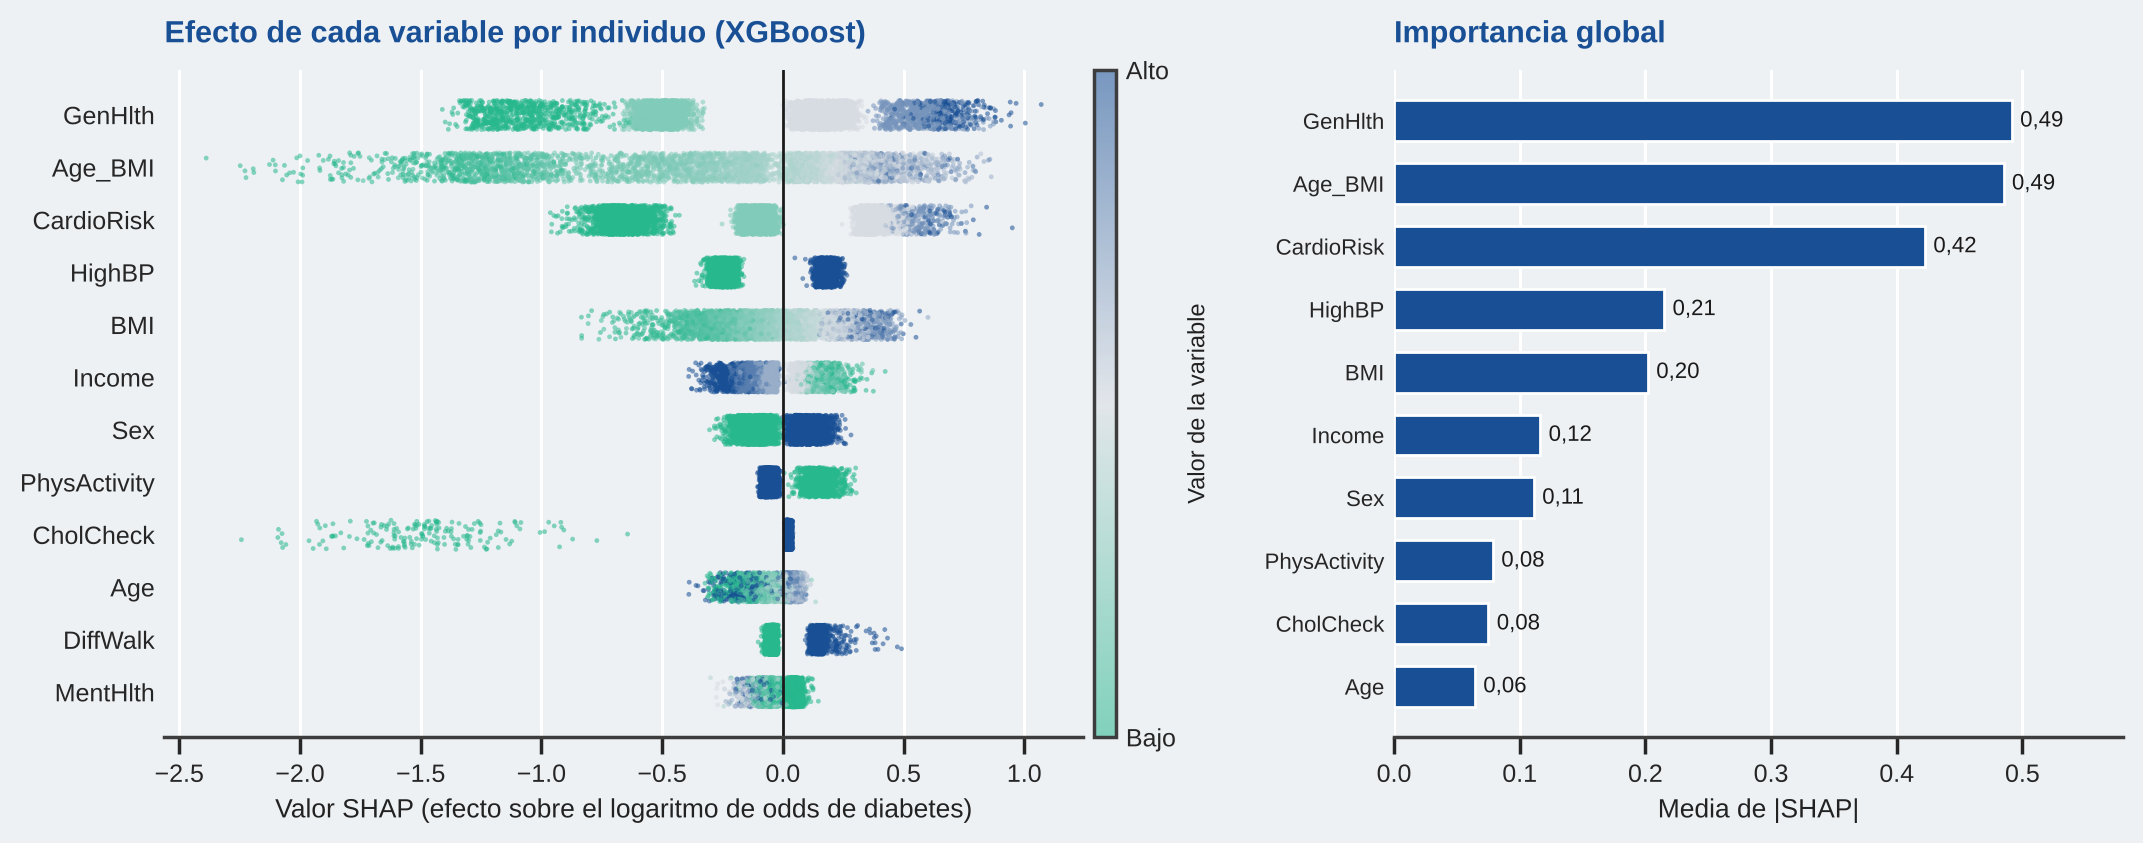

In [19]:
top = list(imp.index[:12])[::-1]; rj = np.random.default_rng(1)
fig, axs = plt.subplots(1, 2, figsize=(10.8, 4.3), gridspec_kw={"width_ratios": [1.5, 1]})
for i, f in enumerate(top):
    j = FEAT.index(f); v = Xs[f].values; vn = (v - v.min()) / (v.max() - v.min() + 1e-12)
    sc = axs[0].scatter(sv[:, j], i + rj.uniform(-.28, .28, len(v)), c=vn, cmap=LinearSegmentedColormap.from_list("m_a", [MENTA, "#d8dde3", AZUL]), s=3, alpha=.55, linewidths=0, rasterized=True)
axs[0].axvline(0, color=TINTA, lw=1); axs[0].set_yticks(range(len(top)), top); axs[0].grid(axis="y", visible=False); axs[0].grid(axis="x", color="white")
axs[0].set(xlabel="Valor SHAP (efecto sobre el logaritmo de odds de diabetes)", title="Efecto de cada variable por individuo (XGBoost)")
cb = fig.colorbar(sc, ax=axs[0], pad=.01, aspect=30); cb.set_ticks([0, 1]); cb.set_ticklabels(["Bajo", "Alto"]); cb.set_label("Valor de la variable", fontsize=8.5)
t10 = imp.head(10)[::-1]; br = axs[1].barh(t10.index, t10.values, color=AZUL, height=.65); axs[1].bar_label(br, labels=[es(v, 2) for v in t10.values], fontsize=8, color=TINTA, padding=3)
axs[1].grid(axis="y", visible=False); axs[1].grid(axis="x", color="white"); axs[1].set(xlabel="Media de |SHAP|", title="Importancia global", xlim=(0, t10.max() * 1.18)); axs[1].tick_params(axis="y", labelsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig7_shap.png"); plt.show()

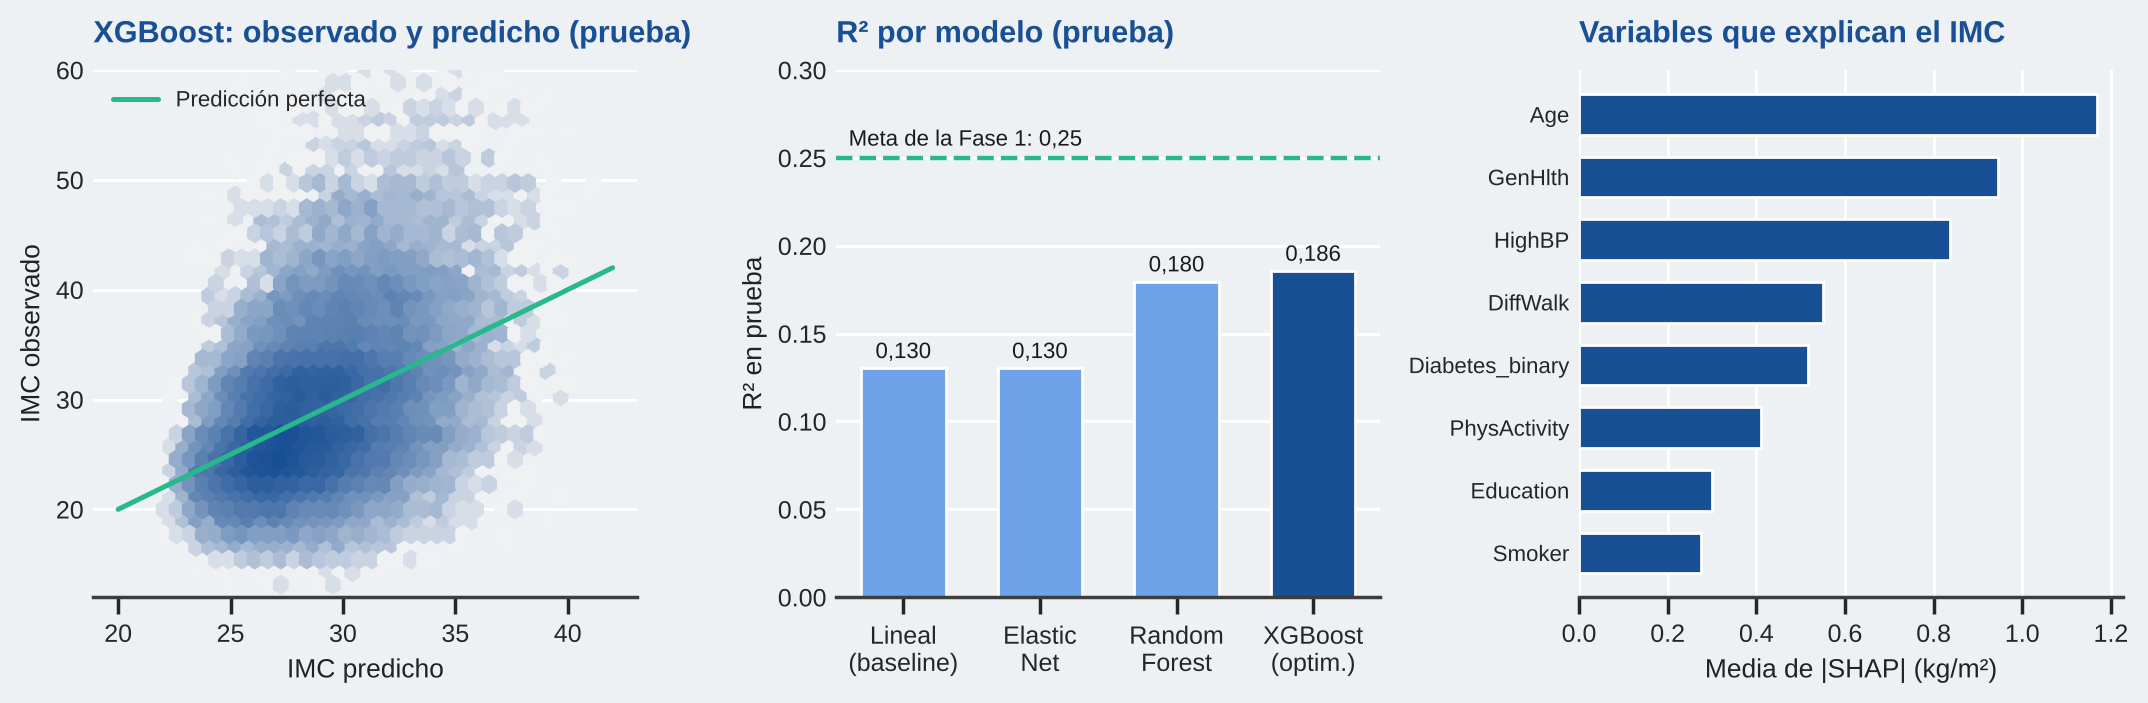

In [20]:
Xr = vars_reg_arbol(Rva.loc[mu.index]); FR = list(Xr.columns)
try: svr = np.asarray(shap.TreeExplainer(xgbr_opt.named_steps["modelo"]).shap_values(Xr))
except Exception: svr = xgbr_opt.named_steps["modelo"].get_booster().predict(xgboost.DMatrix(Xr), pred_contribs=True)[:, :-1]
impr = pd.Series(np.abs(svr).mean(0), index=FR).sort_values(ascending=False); RES["shap_reg"] = {k: float(v) for k, v in impr.items()}
RES["shap_reg_dir"] = {f: float(np.corrcoef(Xr[f], svr[:, FR.index(f)])[0, 1]) for f in impr.index[:8]}
pt = xgbr_opt.predict(Rte); res_t = yte_raw - pt
fig, axs = plt.subplots(1, 3, figsize=(10.8, 3.6))
hb = axs[0].hexbin(pt, yte_raw, gridsize=38, cmap=sns.light_palette(AZUL, as_cmap=True), mincnt=1, bins="log", extent=(20, 42, 12, 60))
axs[0].plot([20, 42], [20, 42], color=MENTA, lw=1.8, label="Predicción perfecta"); axs[0].set(xlabel="IMC predicho", ylabel="IMC observado", title="XGBoost: observado y predicho (prueba)", ylim=(12, 60)); axs[0].legend(loc="upper left", fontsize=8)
tr_ = test_reg[test_reg.Conjunto == "test"].set_index("Modelo"); x = np.arange(len(tr_)); br = axs[1].bar(x, tr_["R²"], color=[CELESTE, CELESTE, CELESTE, AZUL], width=.62)
axs[1].bar_label(br, labels=[es(v, 3) for v in tr_["R²"]], fontsize=8, color=TINTA, padding=2); axs[1].axhline(.25, color=MENTA, lw=1.6, ls="--"); axs[1].text(-.4, .257, "Meta de la Fase 1: 0,25", fontsize=8, color=TINTA)
axs[1].set_xticks(x, ["Lineal\n(baseline)", "Elastic\nNet", "Random\nForest", "XGBoost\n(optim.)"]); axs[1].set(ylabel="R² en prueba", title="R² por modelo (prueba)", ylim=(0, .3))
t8 = impr.head(8)[::-1]; axs[2].barh(t8.index, t8.values, color=AZUL, height=.65); axs[2].grid(axis="y", visible=False); axs[2].grid(axis="x", color="white")
axs[2].set(xlabel="Media de |SHAP| (kg/m²)", title="Variables que explican el IMC"); axs[2].tick_params(axis="y", labelsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig8_regresion_final.png"); plt.show()

**Lectura.**
- La salud general percibida, la interacción edad × IMC y el número de condiciones cardiometabólicas son las tres variables de mayor efecto; las cinco primeras concentran el 70 % de la importancia total. Dos de las tres son **variables derivadas creadas en la Fase 2**, lo que confirma su valor en modelos no lineales.
- El sentido de los efectos es clínicamente coherente: peor salud percibida, mayor edad e IMC, hipertensión y más comorbilidades aumentan el riesgo; mayor ingreso y actividad física lo reducen.
- La importancia por permutación (calculada sobre las variables originales) y la del Random Forest coinciden en las variables principales, de modo que la conclusión no depende del método.
- En la regresión, el IMC estimado disminuye con la edad y aumenta con peor salud percibida, hipertensión, dificultad para caminar y diabetes.

## 9. Contraste con los objetivos, exportación de artefactos y lista de chequeo

In [21]:
tm = test_clf[(test_clf.Modelo == MEJOR)]; f1_05, f1_u = float(tm.iloc[0]["F1"]), float(tm.iloc[1]["F1"]); r2_t = float(test_reg[(test_reg.Modelo == "XGBoost (optimizado)") & (test_reg.Conjunto == "test")]["R²"].iloc[0])
RES["objetivos"] = {"f1_meta": 0.70, "f1_mejor_05": f1_05, "f1_mejor_umbral": f1_u, "f1_ponderado": float(tm.iloc[1]["F1 ponderado"]), "r2_meta": 0.25, "r2_mejor": r2_t,
                    "silueta_k": float(silueta[ks.index(K)])}
# Techo teórico del F1: con el mejor ordenamiento posible del modelo, F1 máximo alcanzable en prueba al variar el umbral
pr_, rc_, _ = precision_recall_curve(y_test, pm); RES["objetivos"]["f1_max_prueba"] = float(np.max(2 * pr_ * rc_ / (pr_ + rc_ + 1e-12)))
todos = vars_cluster(X_all); lab_all = pd.Series(km.predict(esc_cl.transform(todos))).map(mapa).values
pd.DataFrame({"cluster": lab_all}, index=X_all.index).to_csv(ART / "clusters_kmeans.csv", index_label="fila")
joblib.dump(xgb_opt, ART / "modelo_clasificacion_xgboost.joblib"); joblib.dump(xgbr_opt, ART / "modelo_regresion_xgboost.joblib")
joblib.dump({"escalador": esc_cl, "kmeans": km, "mapa": mapa, "variables": CL_VARS, "limites_imc": (lo, hi)}, ART / "modelo_clustering_kmeans.joblib")
torch.save({"estado": red.state_dict(), "n_entrada": int(Ttr.shape[1])}, ART / "mlp_pytorch.pt"); joblib.dump(prep_mlp, ART / "preprocesador_mlp.joblib")
RES["versiones"] = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
                    "torch": torch.__version__.split("+")[0], "shap": shap.__version__, "matplotlib": mpl.__version__, "seaborn": sns.__version__}
RES["tiempo_total_s"] = time.time() - T0
json.dump(RES, open(ART / "resultados_fase3.json", "w", encoding="utf-8"), indent=1, ensure_ascii=False, default=float)
print(f"F1 clase diabetes (prueba): {f1_05:.3f} con umbral 0,5 | {f1_u:.3f} con umbral optimizado | máximo alcanzable {RES['objetivos']['f1_max_prueba']:.3f} | meta 0,70")
print(f"R² del IMC (prueba): {r2_t:.3f} | meta 0,25   ·   Tiempo total de ejecución: {RES['tiempo_total_s']/60:.1f} min")
# Conclusión: las metas de la Fase 1 (F1 >= 0,70 y R² >= 0,25) no se alcanzan. El F1 máximo posible con el mejor modelo es 0,46; ningún umbral lo acerca a 0,70.
pd.DataFrame({"Requisito de la guía (Fase 3)": ["Regresión lineal multivariable regularizada (Lasso, Ridge o ElasticNet)", "Ensamble de regresión (Random Forest o XGBoost)",
    "Dos algoritmos de clasificación distintos", "K-Means con método del codo y coeficiente de silueta", "Segundo algoritmo no supervisado (DBSCAN o jerárquico)",
    "Interpretación de los clústeres", "MLP en PyTorch con gráfica de la función de pérdida", "Búsqueda de hiperparámetros con validación cruzada",
    "Interpretabilidad (SHAP / importancia de variables)", "Métricas completas y diagnóstico de sobreajuste"],
  "Dónde se cumple": ["Sección 2", "Sección 2", "Sección 3 (Random Forest y XGBoost)", "Sección 4.1", "Sección 4.3 (DBSCAN y jerárquico)", "Sección 4.2", "Sección 6", "Sección 5", "Sección 8", "Secciones 2, 3 y 7"]})

F1 clase diabetes (prueba): 0.441 con umbral 0,5 | 0.462 con umbral optimizado | máximo alcanzable 0.464 | meta 0,70
R² del IMC (prueba): 0.186 | meta 0,25   ·   Tiempo total de ejecución: 6.7 min


,Requisito de la guía (Fase 3),Dónde se cumple
0,"Regresión lineal multivariable regularizada (Lasso, Ridge o ElasticNet)",Sección 2
1,Ensamble de regresión (Random Forest o XGBoost),Sección 2
2,Dos algoritmos de clasificación distintos,Sección 3 (Random Forest y XGBoost)
3,K-Means con método del codo y coeficiente de silueta,Sección 4.1
4,Segundo algoritmo no supervisado (DBSCAN o jerárquico),Sección 4.3 (DBSCAN y jerárquico)
5,Interpretación de los clústeres,Sección 4.2
6,MLP en PyTorch con gráfica de la función de pérdida,Sección 6
7,Búsqueda de hiperparámetros con validación cruzada,Sección 5
8,Interpretabilidad (SHAP / importancia de variables),Sección 8
9,Métricas completas y diagnóstico de sobreajuste,"Secciones 2, 3 y 7"
